# IT3091 Machine Learning – Bank Marketing: Campaign Response Prediction
**Group 2026-DS-02 · Lab group Y3.S1.WD.DS.0102 · Guided Data Track (Banking & Finance)**

| Student No | Name | Model | Main part |
|---|---|---|---|
| IT24103860 | Karunathilaka S.H.T.R | Logistic Regression (baseline) | Part 1: data understanding & EDA |
| IT24104178 | Jayasuriya J.A.Y.N | Decision Tree | Part 2: preprocessing; segment rules & fairness (Part 6) |
| IT24104110 | Thulmanthi W.A.S | Random Forest (final model) | Part 6: interpretation; Part 7: final model |
| IT24103869 | Thennakoon T.M.S.D | XGBoost | Part 3: validation; Part 5: test evaluation |

## Project overview
- **Problem:** a Portuguese bank phones clients to sell a term deposit, but only about **1 in 9** says yes, so most calls are wasted.
- **Goal (primary lens: campaign response prediction):** before calling, give every client a score and **rank** them, so the most likely subscribers are called first.
- **Secondary lens (marketing profile analysis):** explain *which* client and campaign characteristics are linked to subscribing.
- **Data:** UCI Bank Marketing, `bank-additional-full.csv` — 41,188 client contacts (May 2008 – Nov 2010), 20 inputs, target `y` (yes/no).
- **ML task:** supervised binary classification, judged as a ranking problem (PR-AUC).

The decision log, data dictionary summary, model comparison and recommendations are presented in the **final report**; this notebook
contains the code and outputs behind them. Run with **Kernel → Restart & Run All**.

## Project flow
| Part | What happens | Main output |
|---|---|---|
| **1. Data understanding & EDA** | Load the data, understand every column, find patterns and data-quality issues | List of issues and signals to act on |
| **2. Preprocessing** | Clean the rows, split train/test, choose features, build pipelines, handle imbalance | Clean, leakage-free training and test sets |
| **3. Validation design** | Decide how models are judged; check leakage and time drift | Metrics (PR-AUC), 5-fold CV, reference floor |
| **4. Modelling** | Tune 4 models: Logistic Regression (baseline), Decision Tree, Random Forest, XGBoost | Model comparison, shortlist |
| **5. Test evaluation** | Score the locked test set once; confidence intervals; thresholds; business view | Honest performance and call-list rules |
| **6. Interpretation** | What drives the predictions; customer profiles; fairness check | Marketing profiles |
| **7. Final model** | Choose the final model and operating rule; verify on the test set | Final Random Forest |

## Workflow diagram
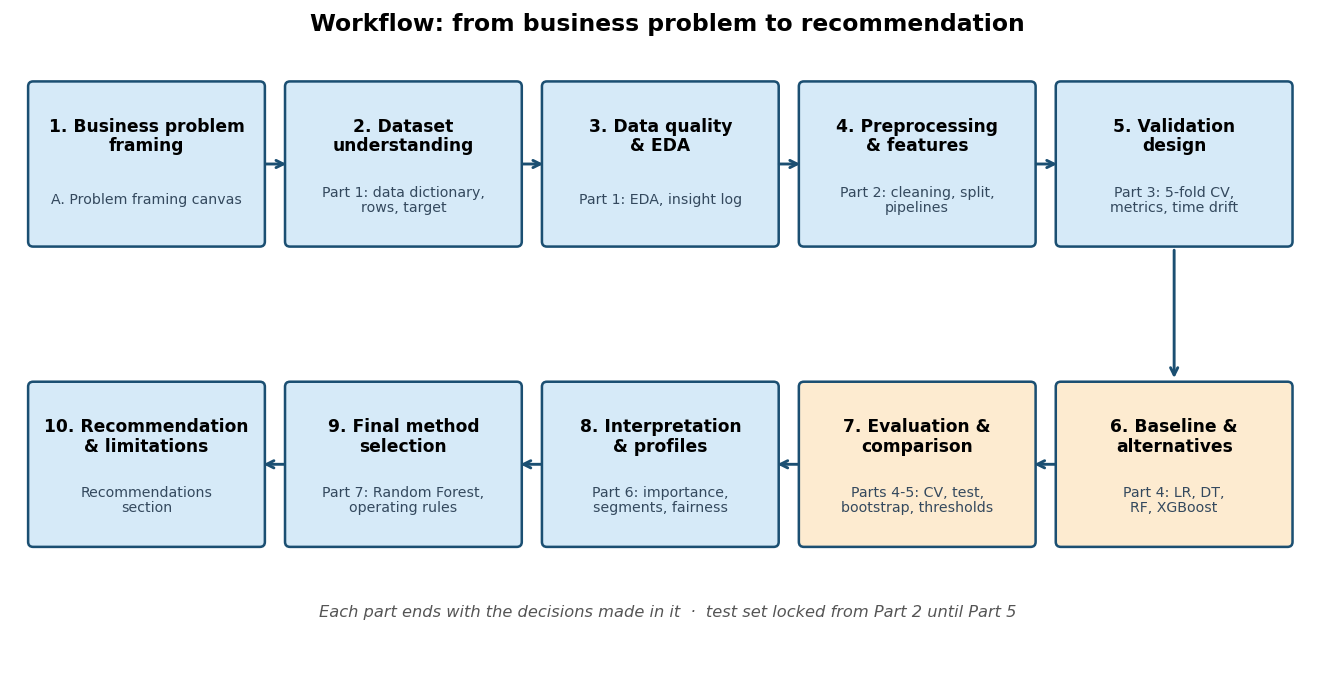

# Part 1 – Data Understanding and EDA
**Owner:** Karunathilaka S.H.T.R

**Goal:** understand the data before modelling. **What we do:** load the data once, describe every column, look at the target,
distributions, relationships with the target, data quality and the time pattern. **Output:** a list of findings that decide the
preprocessing in Part 2. The data is not changed in this part.

## 1.1 Imports
**What the code does:** loads every library used in the notebook (pandas/numpy for data, matplotlib/seaborn for charts, scikit-learn, XGBoost and imbalanced-learn for modelling).

In [1]:
# All libraries used in the notebook
import pickle
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score, confusion_matrix,
                             f1_score, make_scorer, precision_recall_curve, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, RandomizedSearchCV, StratifiedKFold, TimeSeriesSplit,
                                     cross_val_predict, cross_validate, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.class_weight import compute_class_weight
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

## 1.2 Settings
**What the code does:** keeps all fixed choices in one place: the data path, the random seed (42), the target, the feature groups, preprocessing settings and the 5-fold cross-validation object used by every model.

In [2]:
# Paths (works whether the notebook is opened from the project folder or from notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_FILE = ROOT / "data" / "raw" / "bank-additional-full.csv"
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)

# Reproducibility: the same seed for the split, the CV folds and every model (D4)
RANDOM_STATE = 42
TEST_SIZE = 0.20

# Target
TARGET = "y"
POSITIVE_CLASS = "yes"

# Feature groups (from the dataset documentation)
CLIENT_FEATURES = ["age", "job", "marital", "education", "default", "housing", "loan"]
CONTACT_FEATURES = ["contact", "month", "day_of_week", "duration"]
CAMPAIGN_FEATURES = ["campaign", "pdays", "previous", "poutcome"]
ECONOMIC_FEATURES = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
LEAKAGE_FEATURES = ["duration"]          # only known after the call (D3)
MISSING_TOKEN = "unknown"                # missing categorical values are coded as "unknown"
PDAYS_NOT_CONTACTED = 999                # placeholder: client not previously contacted

# Preprocessing settings (decided in Part 2)
CAMPAIGN_CAP = 10                                    # D9
EDUCATION_MERGE = {"illiterate": "basic.4y"}         # D14
AGE_BINS = [16, 25, 30, 40, 50, 60, 70, 120]         # age groups for the linear model (U-shape)
AGE_LABELS = ["17-25", "26-30", "31-40", "41-50", "51-60", "61-70", "71+"]
CAT_FEATURES = ["job", "marital", "education", "default", "housing", "loan",
                "contact", "month", "day_of_week", "poutcome"]
NUM_FEATURES = ["age", "campaign", "previous", "contacted_before"]
ECON_FEATURES_LINEAR = ["euribor3m", "cons.price.idx", "cons.conf.idx"]   # D11: one of the 3 collinear indicators
DROPPED_FEATURES = ["housing", "loan"]               # D15, verified in section 2.3
MONTHS = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]

# Validation: the same 5 stratified folds for every model (D18)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
TOP_FRACTION = 0.20                      # business metric: share of subscribers in the top 20% of scores

# Display settings
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

## 1.3 Helper functions
**What the code does:** defines small functions used in several parts. The most important are:
- `clean_rows` – the fixed cleaning rules (Part 2);
- `build_preprocessor` – the two preprocessing pipelines (linear for Logistic Regression, tree for the other models);
- `evaluate_cv` / `score_predictions` – compute all metrics (PR-AUC, ROC-AUC, recall, precision, F1, accuracy, top-20% capture);
- `chi_square_table`, `vif_table` – statistical checks used in EDA and preprocessing.

In [3]:
def save_fig(name):
    # Save the current chart to figures/ (for the report) and show it
    plt.tight_layout()
    plt.savefig(FIGURES / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


def clean_rows(df):
    # Row-level cleaning with fixed rules (learns nothing from the data, so it is safe before the split)
    out = df.drop_duplicates().reset_index(drop=True)                       # D8: remove exact duplicates
    out = out.drop(columns=LEAKAGE_FEATURES)                                # D3: remove post-call leakage
    out["contacted_before"] = (out["previous"] > 0).astype(int)             # D10: flag replaces pdays
    out = out.drop(columns=["pdays"])
    out["default"] = np.where(out["default"] == "no", "no", "not_no")       # D13: merge the 3 "yes" rows
    out["education"] = out["education"].replace(EDUCATION_MERGE)            # D14: merge rare level
    out["campaign"] = out["campaign"].clip(upper=CAMPAIGN_CAP)              # D9: cap extreme call counts
    out[TARGET] = (out[TARGET] == POSITIVE_CLASS).astype(int)               # yes -> 1, no -> 0
    return out


def bin_age(X):
    # Replace numeric age with an age-group label (linear model only)
    return X.assign(age=pd.cut(X["age"], bins=AGE_BINS, labels=AGE_LABELS).astype(str))


def feature_lists(kind, drop=None):
    # Categorical and numeric inputs for a pipeline: "linear" (Logistic Regression) or "tree" (DT, RF, XGBoost)
    drop = set(DROPPED_FEATURES if drop is None else drop)
    cats = [c for c in CAT_FEATURES if c not in drop]
    if kind == "linear":
        nums = [c for c in NUM_FEATURES if c != "age"] + ECON_FEATURES_LINEAR
    else:
        nums = NUM_FEATURES + ECONOMIC_FEATURES
    return cats, [c for c in nums if c not in drop]


def one_hot():
    # One-hot encoder that ignores categories not seen during training
    return OneHotEncoder(handle_unknown="ignore", sparse_output=False)


def build_preprocessor(kind, drop=None):
    # Unfitted ColumnTransformer: linear = one-hot + age groups + scaling; tree = one-hot + raw numbers
    cats, nums = feature_lists(kind, drop)
    if kind == "linear":
        age_pipe = Pipeline([("bin", FunctionTransformer(bin_age, feature_names_out="one-to-one")),
                             ("onehot", one_hot())])
        parts = [("cat", one_hot(), cats), ("age", age_pipe, ["age"]), ("num", StandardScaler(), nums)]
    else:
        parts = [("cat", one_hot(), cats), ("num", "passthrough", nums)]
    return ColumnTransformer(parts, remainder="drop", verbose_feature_names_out=False)


def reconstruct_year(month):
    # Approximate year of each row from the date order (a new year starts when the month number goes back)
    month_num = month.map({m: i for i, m in enumerate(MONTHS, start=1)})
    return 2008 + (month_num.diff() < 0).cumsum()


def top_k_capture(y_true, y_score, fraction=TOP_FRACTION):
    # Share of all subscribers found when calling only the top `fraction` of clients by score
    y_true = np.asarray(y_true)
    n_top = int(np.ceil(fraction * len(y_true)))
    top_idx = np.argsort(-np.asarray(y_score), kind="stable")[:n_top]
    return y_true[top_idx].sum() / y_true.sum()


def top_capture_scorer(estimator, X, y):
    # Scorer version of top_k_capture for cross-validation
    return top_k_capture(y, estimator.predict_proba(X)[:, 1])


# Metrics computed in every cross-validation (PR-AUC is the primary metric, D18)
SCORING = {
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "balanced_acc": "balanced_accuracy",
    "accuracy": "accuracy",
    "top20_capture": top_capture_scorer,
}


def evaluate_cv(model, X, y, name, cv=CV):
    # Cross-validate a full pipeline and return mean/std of every metric (plus per-fold scores)
    scores = cross_validate(model, X, y, cv=cv, scoring=SCORING)
    row = {"model": name}
    for metric in SCORING:
        row[f"{metric}_mean"] = scores[f"test_{metric}"].mean()
        row[f"{metric}_std"] = scores[f"test_{metric}"].std()
    row["fit_time_s"] = scores["fit_time"].mean()
    row["fold_scores"] = {metric: scores[f"test_{metric}"] for metric in SCORING}
    return row


def cv_table(rows, metrics=("pr_auc", "roc_auc", "recall", "precision", "f1", "balanced_acc", "accuracy", "top20_capture")):
    # Format evaluate_cv results as a readable "mean ± std" table
    df = pd.DataFrame(rows).drop(columns="fold_scores", errors="ignore").set_index("model")
    out = pd.DataFrame(index=df.index)
    for m in metrics:
        out[m] = df[f"{m}_mean"].map("{:.3f}".format) + " ± " + df[f"{m}_std"].map("{:.3f}".format)
    return out


def paired_comparison(rows, baseline, metric="pr_auc"):
    # Compare each model with the baseline fold by fold (all models share the same folds)
    by_name = {r["model"]: r["fold_scores"][metric] for r in rows}
    out = []
    for name, folds in by_name.items():
        if name != baseline:
            diff = folds - by_name[baseline]
            out.append({"model": name, f"mean_{metric}_diff_vs_baseline": diff.mean(),
                        "std_of_diff": diff.std(), "folds_better": f"{(diff > 0).sum()}/{len(diff)}"})
    return pd.DataFrame(out).set_index("model")


def score_predictions(y_true, y_score, threshold=0.5):
    # All metrics for one set of predicted scores (used on the test set)
    y_pred = (np.asarray(y_score) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {"pr_auc": average_precision_score(y_true, y_score), "roc_auc": roc_auc_score(y_true, y_score),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0), "f1": f1_score(y_true, y_pred, zero_division=0),
            "balanced_acc": balanced_accuracy_score(y_true, y_pred), "accuracy": accuracy_score(y_true, y_pred),
            "top20_capture": top_k_capture(y_true, y_score), "TP": tp, "FP": fp, "FN": fn, "TN": tn}


def chi_square_table(data, columns, target):
    # Chi-square test of independence between each categorical column and the target
    rows = []
    for c in columns:
        chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(data[c], target))
        rows.append({"feature": c, "chi2": round(chi2, 1), "dof": dof, "p_value": p})
    return pd.DataFrame(rows).set_index("feature").sort_values("chi2", ascending=False)


def vif_table(data):
    # Variance Inflation Factor: how well each numeric column is explained by the others (VIF > 10 = severe)
    rows = []
    for c in data.columns:
        others = data.drop(columns=c)
        r2 = LinearRegression().fit(others, data[c]).score(others, data[c])
        rows.append({"feature": c, "VIF": round(1 / (1 - r2), 1) if r2 < 1 else np.inf})
    return pd.DataFrame(rows).set_index("feature")

## 1.4 Load the data
**What the code does:** reads the CSV (separator `;`) once into `raw`, which is never changed, and makes a working copy `df` with a numeric target (1 = subscribed) for calculating rates.

In [4]:
# Load the dataset and keep an untouched copy
raw = pd.read_csv(DATA_FILE, sep=";")
FEATURES = [c for c in raw.columns if c != TARGET]
NUM_COLS = raw[FEATURES].select_dtypes("number").columns.tolist()
CAT_COLS = [c for c in FEATURES if c not in NUM_COLS]

# Working copy for EDA with a numeric target (1 = subscribed) to compute rates
df = raw.copy()
df["y_num"] = (df[TARGET] == POSITIVE_CLASS).astype(int)
OVERALL_RATE = df["y_num"].mean()

print("Shape:", raw.shape)
print(f"Overall subscription rate: {OVERALL_RATE:.2%}")
print(f"Numeric features ({len(NUM_COLS)}):", NUM_COLS)
print(f"Categorical features ({len(CAT_COLS)}):", CAT_COLS)
raw.head()

Shape: (41188, 21)
Overall subscription rate: 11.27%
Numeric features (10): ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categorical features (10): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


**What this shows**
- 41,188 rows and 21 columns: 10 numeric and 10 categorical inputs plus the target `y`.
- Only **11.27%** subscribed, so the classes are strongly imbalanced.

➡️ **Next:** describe what every column means.

## 1.5 Data dictionary
**What the code does:** builds a table with each column's group, type, meaning, values, number of `unknown` values and whether it is **known before the call** (the leakage check).

In [5]:
# Meaning, type and "known before the call?" for every column
DESCRIPTIONS = {
    "age": "Client age in years", "job": "Type of job", "marital": "Marital status ('divorced' includes widowed)",
    "education": "Education level", "default": "Has credit in default?", "housing": "Has a housing loan?",
    "loan": "Has a personal loan?", "contact": "Contact communication type", "month": "Month of the last contact",
    "day_of_week": "Weekday of the last contact", "duration": "Duration of the last contact in seconds",
    "campaign": "Number of contacts in this campaign for this client (includes the last contact)",
    "pdays": "Days since last contact in a previous campaign (999 = never contacted)",
    "previous": "Number of contacts before this campaign", "poutcome": "Outcome of the previous campaign",
    "emp.var.rate": "Employment variation rate (quarterly)", "cons.price.idx": "Consumer price index (monthly)",
    "cons.conf.idx": "Consumer confidence index (monthly)", "euribor3m": "Euribor 3-month interest rate (daily)",
    "nr.employed": "Number of employees, thousands (quarterly)", "y": "TARGET - subscribed to a term deposit?",
}
KIND = {
    "age": "numeric", "job": "nominal", "marital": "nominal", "education": "ordinal", "default": "binary + unknown",
    "housing": "binary + unknown", "loan": "binary + unknown", "contact": "binary", "month": "cyclical/nominal",
    "day_of_week": "cyclical/nominal", "duration": "numeric", "campaign": "numeric (count)",
    "pdays": "numeric with placeholder", "previous": "numeric (count)", "poutcome": "nominal",
    "emp.var.rate": "numeric", "cons.price.idx": "numeric", "cons.conf.idx": "numeric", "euribor3m": "numeric",
    "nr.employed": "numeric", "y": "binary target",
}
KNOWN_BEFORE_CALL = {**{c: "Yes" for c in CLIENT_FEATURES}, "contact": "Yes (planned channel)",
                     "month": "Yes (planned date)", "day_of_week": "Yes (planned date)",
                     "duration": "NO - only after the call (leakage)", "campaign": "Partly - grows during the campaign",
                     "pdays": "Yes", "previous": "Yes", "poutcome": "Yes",
                     **{c: "Yes (public indicator)" for c in ECONOMIC_FEATURES}, "y": "Target"}
GROUP = {c: g for g, cols in {"client": CLIENT_FEATURES, "contact": CONTACT_FEATURES, "campaign history": CAMPAIGN_FEATURES,
                              "economic context": ECONOMIC_FEATURES, "target": [TARGET]}.items() for c in cols}

rows = []
for c in raw.columns:
    s = raw[c]
    values = f"{s.min():g} to {s.max():g}" if pd.api.types.is_numeric_dtype(s) else ", ".join(sorted(s.unique()))
    n_unknown = int((s.astype(str) == MISSING_TOKEN).sum())
    rows.append({"column": c, "group": GROUP[c], "type": KIND[c], "description": DESCRIPTIONS[c],
                 "values / range": values, "n_unique": s.nunique(), "n_unknown": n_unknown,
                 "pct_unknown": round(100 * n_unknown / len(raw), 2), "known_before_call": KNOWN_BEFORE_CALL[c]})
data_dictionary = pd.DataFrame(rows).set_index("column")
data_dictionary

,group,type,description,values / range,n_unique,n_unknown,pct_unknown,known_before_call
column,,,,,,,,
age,client,numeric,Client age in years,17 to 98,78,0,0.00,Yes
job,client,nominal,Type of job,"admin., blue-collar, entrepreneur, housemaid, management, retired, self-employed, services, student, technician, une...",12,330,0.80,Yes
marital,client,nominal,Marital status ('divorced' includes widowed),"divorced, married, single, unknown",4,80,0.19,Yes
education,client,ordinal,Education level,"basic.4y, basic.6y, basic.9y, high.school, illiterate, professional.course, university.degree, unknown",8,1731,4.20,Yes
default,client,binary + unknown,Has credit in default?,"no, unknown, yes",3,8597,20.87,Yes
housing,client,binary + unknown,Has a housing loan?,"no, unknown, yes",3,990,2.40,Yes
loan,client,binary + unknown,Has a personal loan?,"no, unknown, yes",3,990,2.40,Yes
contact,contact,binary,Contact communication type,"cellular, telephone",2,0,0.00,Yes (planned channel)
month,contact,cyclical/nominal,Month of the last contact,"apr, aug, dec, jul, jun, mar, may, nov, oct, sep",10,0,0.00,Yes (planned date)


**What this shows**
- Every input is known before a call **except `duration`** (call length), which is only known afterwards, so it is leakage and must be removed.
- Missing values are written as `"unknown"`; `default` is the worst (20.87%).

➡️ **Next:** check what one row represents.

## 1.6 What does a row represent?
**What the code does:** counts duplicate rows, checks for identical rows with different answers, and checks that rows are in date order (months in calendar order) to estimate the year of each row.

In [6]:
# Exact duplicates, and identical feature values with a different target (label conflicts)
n_dup = raw.duplicated().sum()
conflicts = raw.groupby(FEATURES, dropna=False)[TARGET].nunique().gt(1).sum()
print(f"Exact duplicate rows:                  {n_dup}")
print(f"Feature combinations with conflicting y: {conflicts}")

# Month blocks in row order: date-ordered data shows months in calendar order, restarting each year
month_blocks = raw.loc[raw["month"].ne(raw["month"].shift()), "month"].tolist()
print(f"Month blocks in row order ({len(month_blocks)}):", " -> ".join(month_blocks))

# Approximate year of each row (analysis only - never used as a model feature)
df["eda_year"] = reconstruct_year(df["month"])
df["eda_period"] = df["eda_year"].astype(str) + "-" + df["month"].map({m: i for i, m in enumerate(MONTHS, 1)}).astype(str).str.zfill(2)
months_present = [m for m in MONTHS if m in raw["month"].unique()]
year_month = pd.crosstab(df["eda_year"], df["month"]).reindex(columns=months_present)
year_month["total"] = year_month.sum(axis=1)
year_month

Exact duplicate rows:                  12
Feature combinations with conflicting y: 0
Month blocks in row order (26): may -> jun -> jul -> aug -> oct -> nov -> dec -> mar -> apr -> may -> jun -> jul -> aug -> sep -> oct -> nov -> dec -> mar -> apr -> may -> jun -> jul -> aug -> sep -> oct -> nov


month,mar,apr,may,jun,jul,aug,sep,oct,nov,dec,total
eda_year,,,,,,,,,,,
2008,0,0,7763,4374,6685,5175,0,67,3616,10,27690
2009,282,2458,5794,715,178,770,267,447,357,172,11440
2010,264,174,212,229,311,233,303,204,128,0,2058


**What this shows**
- One row = one client contact in a campaign; there is no client ID. There are **12 exact duplicates** and no conflicting labels.
- Rows are in date order (2008: 27,690, 2009: 11,440, 2010: 2,058 rows), which lets us check time effects later.

➡️ **Next:** look at the target.

## 1.7 Target variable
**What the code does:** plots how many clients said yes and no, and shows the accuracy of a model that always says no.

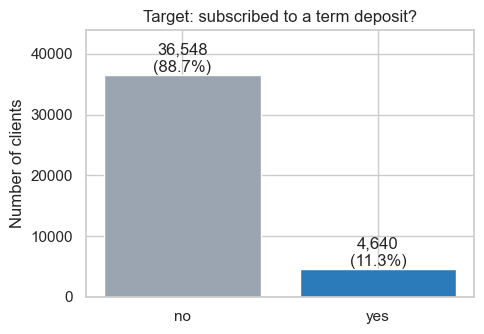

Imbalance ratio (no : yes) = 7.9 : 1
Always predicting 'no' gives 88.73% accuracy but finds 0 of 4,640 subscribers.


In [7]:
# Class balance of the target
counts = raw[TARGET].value_counts()
fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar(counts.index, counts.values, color=["#9aa5b1", "#2b7bba"])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v / len(raw):.1%})", ha="center", va="bottom")
ax.set(title="Target: subscribed to a term deposit?", ylabel="Number of clients", ylim=(0, counts.max() * 1.2))
save_fig("fig01_target_distribution")

print(f"Imbalance ratio (no : yes) = {counts['no'] / counts['yes']:.1f} : 1")
print(f"Always predicting 'no' gives {counts['no'] / len(raw):.2%} accuracy but finds 0 of {counts['yes']:,} subscribers.")

**What this shows**
- 36,548 no vs 4,640 yes (7.9 : 1).
- Always saying "no" is **88.73% accurate but finds nobody**, so accuracy cannot be our main metric.

➡️ **Next:** look at the numeric features.

## 1.8 Numeric features and outliers
**What the code does:** shows summary statistics (count, mean, quartiles, skew) of the numeric columns.

In [8]:
# Summary statistics with skewness
num_summary = df[NUM_COLS].describe().T
num_summary["skew"] = df[NUM_COLS].skew()
num_summary.round(3)

,count,mean,std,min,25%,50%,75%,max,skew
age,41188.0,40.024,10.421,17.000,32.000,38.000,47.000,98.000,0.785
duration,41188.0,258.285,259.279,0.000,102.000,180.000,319.000,4918.000,3.263
campaign,41188.0,2.568,2.770,1.000,1.000,2.000,3.000,56.000,4.763
pdays,41188.0,962.475,186.911,0.000,999.000,999.000,999.000,999.000,-4.922
previous,41188.0,0.173,0.495,0.000,0.000,0.000,0.000,7.000,3.832
emp.var.rate,41188.0,0.082,1.571,-3.400,-1.800,1.100,1.400,1.400,-0.724
cons.price.idx,41188.0,93.576,0.579,92.201,93.075,93.749,93.994,94.767,-0.231
cons.conf.idx,41188.0,-40.503,4.628,-50.800,-42.700,-41.800,-36.400,-26.900,0.303
euribor3m,41188.0,3.621,1.734,0.634,1.344,4.857,4.961,5.045,-0.709
nr.employed,41188.0,5167.036,72.252,4963.600,5099.100,5191.000,5228.100,5228.100,-1.044


**What the code does:** draws a histogram for each numeric column (`pdays` without the 999 placeholder).

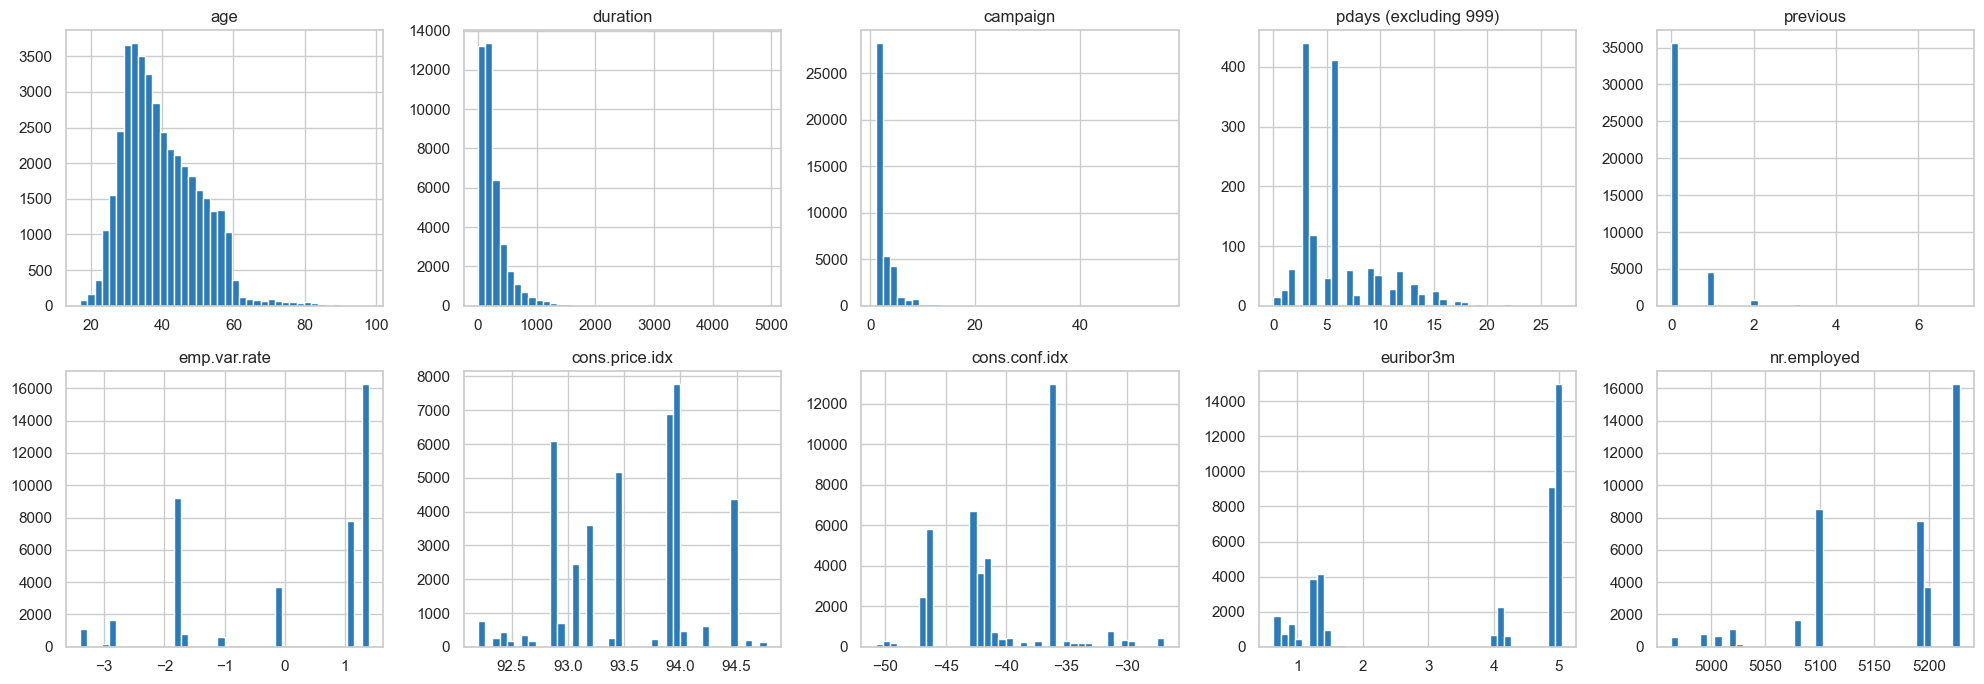

In [9]:
# Histograms (pdays without the 999 placeholder)
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, c in zip(axes.flat, NUM_COLS):
    data = df[c] if c != "pdays" else df.loc[df[c] != PDAYS_NOT_CONTACTED, c]
    ax.hist(data, bins=40, color="#2b7bba", edgecolor="white")
    ax.set_title(c if c != "pdays" else "pdays (excluding 999)")
save_fig("fig02_numeric_histograms")

**What this shows**
- `campaign`, `previous` and `duration` are strongly skewed (most clients have few calls).
- `pdays` is almost always the placeholder 999.

➡️ **Next:** check outliers and whether they behave differently.

**What the code does:** finds outliers with the 1.5 × IQR rule and compares the yes-rate of outlier clients with everyone else.

In [10]:
# Outliers by the 1.5 x IQR rule, and whether outliers subscribe differently from the rest
rows = []
for c in [c for c in NUM_COLS if c != "pdays"]:
    q1, q3 = df[c].quantile([0.25, 0.75])
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    is_out = (df[c] < lo) | (df[c] > hi)
    rows.append({"feature": c, "lower_fence": lo, "upper_fence": hi, "n_outliers": int(is_out.sum()),
                 "pct_outliers": round(100 * is_out.mean(), 2),
                 "yes_rate_if_outlier_%": round(100 * df.loc[is_out, "y_num"].mean(), 2) if is_out.any() else np.nan,
                 "yes_rate_otherwise_%": round(100 * df.loc[~is_out, "y_num"].mean(), 2)})
outliers = pd.DataFrame(rows).set_index("feature")
outliers

,lower_fence,upper_fence,n_outliers,pct_outliers,yes_rate_if_outlier_%,yes_rate_otherwise_%
feature,,,,,,
age,9.5000,69.5000,469,1.14,47.12,10.85
duration,-223.5000,644.5000,2963,7.19,51.50,8.15
campaign,-2.0000,6.0000,2406,5.84,4.61,11.68
previous,0.0000,0.0000,5625,13.66,26.65,8.83
emp.var.rate,-6.6000,6.2000,0,0.00,NaN,11.27
cons.price.idx,91.6965,95.3725,0,0.00,NaN,11.27
cons.conf.idx,-52.1500,-26.9500,447,1.09,40.27,10.95
euribor3m,-4.0815,10.3865,0,0.00,NaN,11.27
nr.employed,4905.6000,5421.6000,0,0.00,NaN,11.27


**What the code does:** draws boxplots for `age`, `campaign` and `previous`, the columns with many outliers.

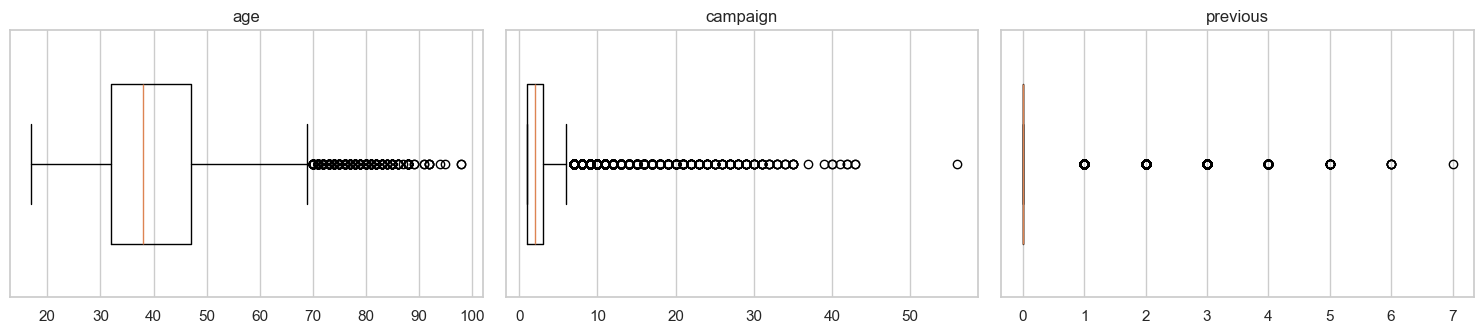

Clients contacted more than 10 times in this campaign: 869


In [11]:
# Boxplots of the three features with many outliers
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, c in zip(axes, ["age", "campaign", "previous"]):
    ax.boxplot(df[c], vert=False, widths=0.6)
    ax.set(title=c, yticks=[])
save_fig("fig03_numeric_boxplots")
print(f"Clients contacted more than 10 times in this campaign: {(df['campaign'] > 10).sum()}")

**What this shows**
- Outliers are **real values**, not errors (ages 70–98, up to 56 calls), and they carry signal: clients over 69.5 subscribe at **47%** vs 11%.
- So no rows are removed; only `campaign` will be capped at 10 (869 clients have more than 10 calls).

➡️ **Next:** look at the categorical features.

## 1.9 Categorical features
**What the code does:** counts the clients in every category; `unknown` values are shown in orange.

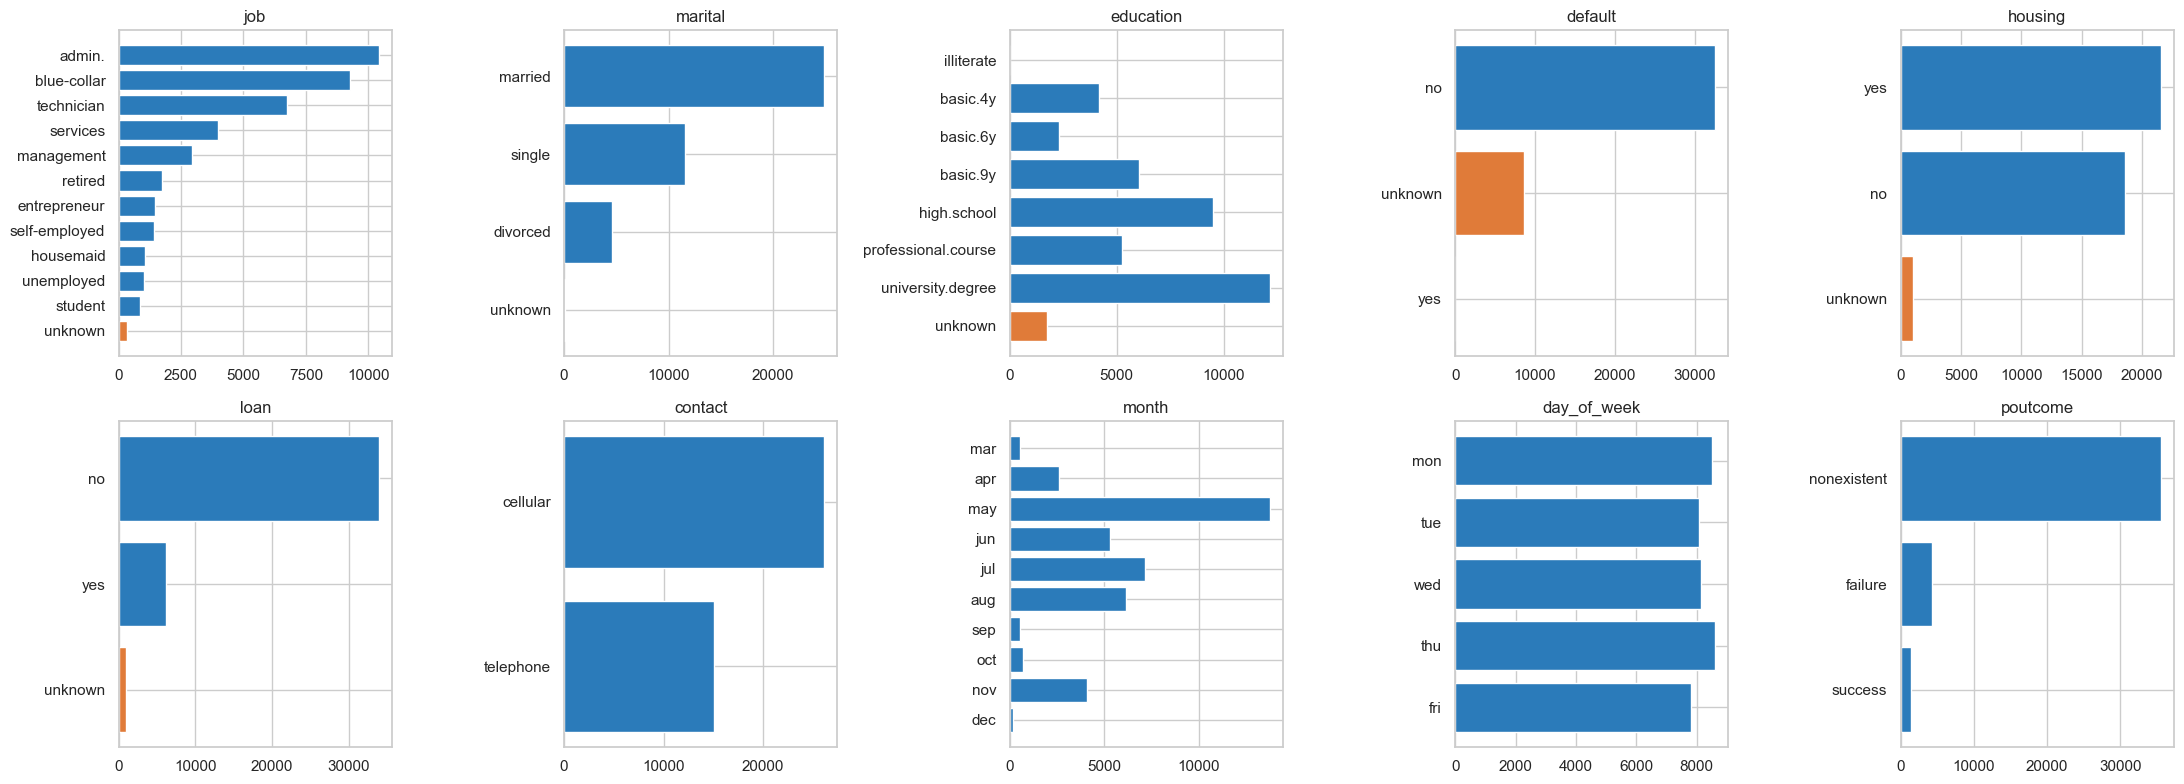

In [12]:
# Fixed display order for ordered categories
ORDERS = {"month": months_present, "day_of_week": ["mon", "tue", "wed", "thu", "fri"],
          "education": ["illiterate", "basic.4y", "basic.6y", "basic.9y", "high.school",
                        "professional.course", "university.degree", "unknown"]}

def category_order(col):
    # Calendar / education order where it exists, otherwise most frequent first
    return ORDERS.get(col, df[col].value_counts().index.tolist())

# Count per category ("unknown" in orange)
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for ax, c in zip(axes.flat, CAT_COLS):
    vc = df[c].value_counts().reindex(category_order(c))
    ax.barh(vc.index.astype(str), vc.values, color=["#e07b39" if k == MISSING_TOKEN else "#2b7bba" for k in vc.index])
    ax.invert_yaxis()
    ax.set_title(c)
save_fig("fig04_categorical_counts")

**What this shows**
- May is by far the busiest month; most clients are admin, blue-collar or technicians.
- `unknown` appears in six columns.

➡️ **Next:** see how each feature relates to subscribing.

## 1.10 Features vs target
### 1.10.1 Subscription rate per category
**What the code does:** calculates and plots the share of clients who subscribed in every category (red line = overall 11.27%).

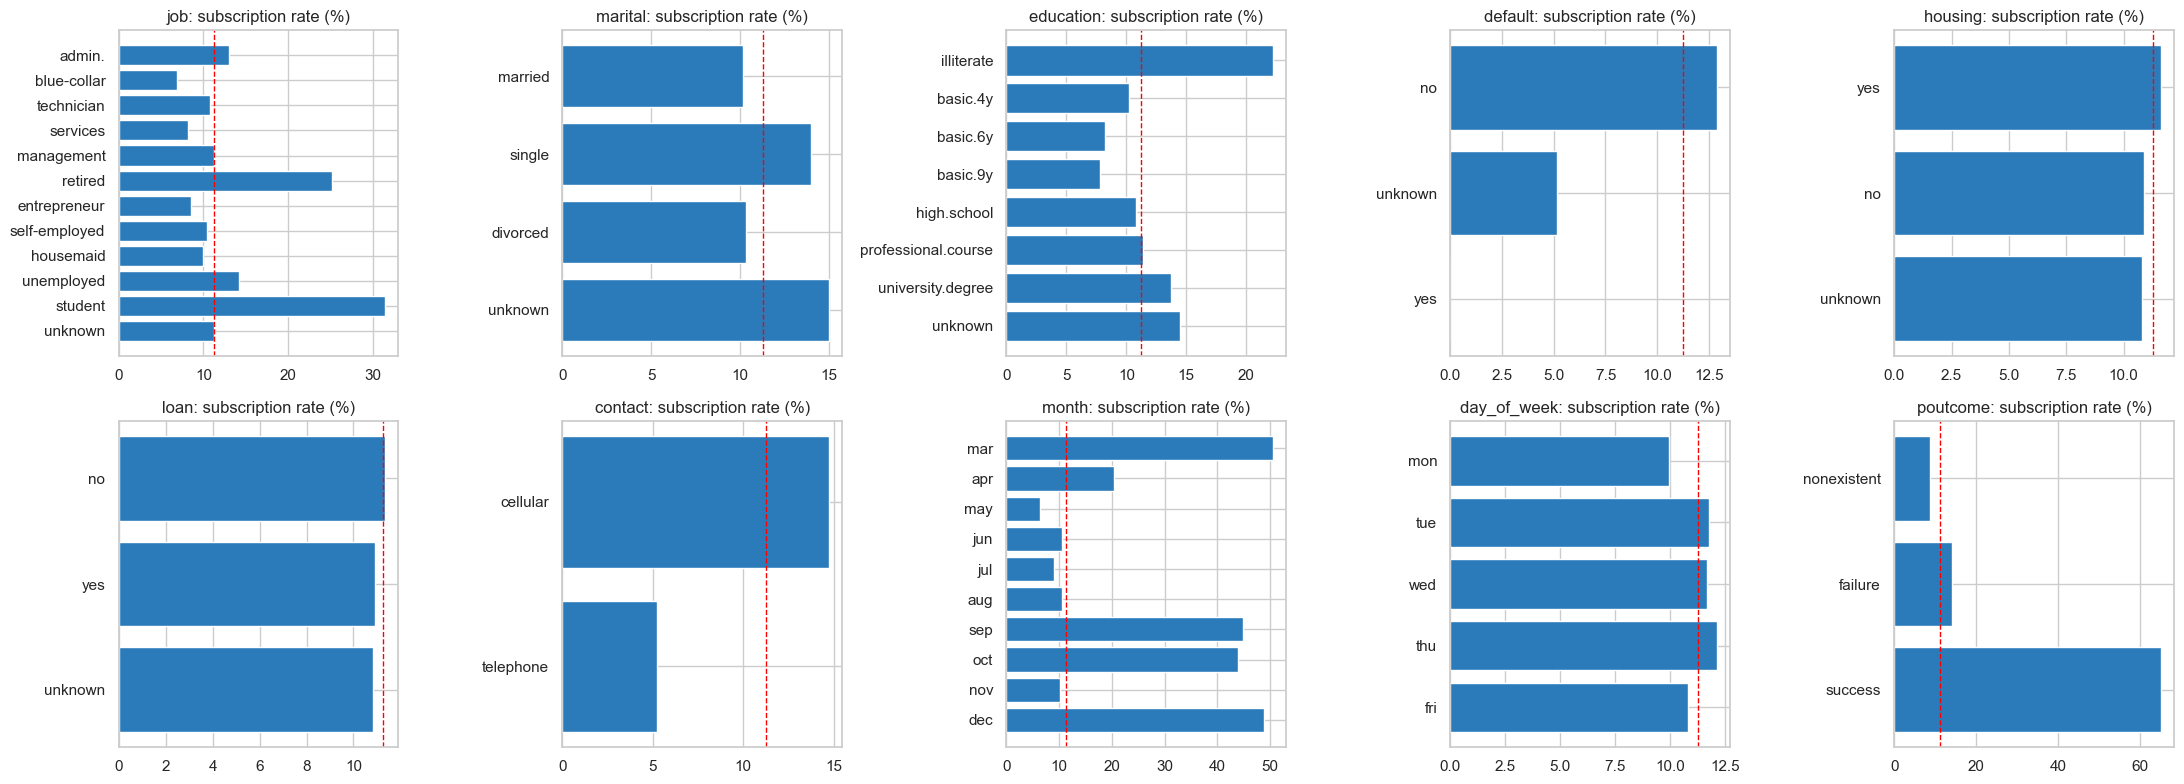


=== job ===
                   n  subscribed   rate  lift_vs_overall
job                                                     
admin.         10422        1352  12.97             1.15
blue-collar     9254         638   6.89             0.61
technician      6743         730  10.83             0.96
services        3969         323   8.14             0.72
management      2924         328  11.22             1.00
retired         1720         434  25.23             2.24
entrepreneur    1456         124   8.52             0.76
self-employed   1421         149  10.49             0.93
housemaid       1060         106  10.00             0.89
unemployed      1014         144  14.20             1.26
student          875         275  31.43             2.79
unknown          330          37  11.21             1.00

=== marital ===
              n  subscribed   rate  lift_vs_overall
marital                                            
married   24928        2532  10.16             0.90
single    11568 

In [13]:
def rate_table(col, data=df):
    # Number of clients, subscribers, yes-rate and lift (rate / overall rate) per group
    t = data.groupby(col, observed=True)["y_num"].agg(n="size", subscribed="sum", rate="mean")
    t["rate"] = (100 * t["rate"]).round(2)
    t["lift_vs_overall"] = (t["rate"] / (100 * OVERALL_RATE)).round(2)
    return t

# Subscription rate per category
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for ax, c in zip(axes.flat, CAT_COLS):
    t = rate_table(c).reindex(category_order(c))
    ax.barh(t.index.astype(str), t["rate"], color="#2b7bba")
    ax.axvline(100 * OVERALL_RATE, color="red", ls="--", lw=1)
    ax.invert_yaxis()
    ax.set_title(f"{c}: subscription rate (%)")
save_fig("fig05_categorical_subscription_rates")

for c in CAT_COLS:
    print(f"\n=== {c} ===")
    print(rate_table(c).reindex(category_order(c)).to_string())

**What this shows**
- Previous campaign success → **65.11%** yes; March/September/October/December → 44–51%; May → only 6.43%.
- Students (31.4%) and retired clients (25.2%) respond best; mobile contact 14.7% vs landline 5.2%.
- `housing` and `loan` hardly change the rate.

➡️ **Next:** test these relationships statistically.

### 1.10.2 Chi-square test
**What the code does:** runs a chi-square test of independence between every categorical feature and the target. A small p-value means the feature and subscribing are related; a larger χ² means a stronger difference between categories.

In [14]:
# Chi-square test for every categorical feature (sorted by chi-square statistic)
chi_eda = chi_square_table(df, CAT_COLS, df[TARGET])
chi_eda

,chi2,dof,p_value
feature,,,
poutcome,4230.5,2,0.000000e+00
month,3101.1,9,0.000000e+00
job,961.2,11,4.189763e-199
contact,862.3,1,1.525986e-189
default,406.6,2,5.161958e-89
education,193.1,7,3.305189e-38
marital,122.7,3,2.068015e-26
day_of_week,26.1,4,2.958482e-05
housing,5.7,2,5.829448e-02


**What this shows**
- `poutcome` (χ² 4,230.5), `month` and `job` are most strongly related to subscribing.
- `housing` (p = 0.058) and `loan` (p = 0.58) are **not significant** → candidates to drop (checked again on training data in 2.3).

➡️ **Next:** numeric features vs target.

### 1.10.3 Numeric features vs target
**What the code does:** compares the values of subscribers and non-subscribers (medians, Mann-Whitney test) and measures how well each feature alone ranks clients (single-feature AUC: 0.5 = random, 1 = perfect).

In [15]:
# Median by outcome, Mann-Whitney test and single-feature AUC
rows = []
for c in NUM_COLS:
    yes_vals, no_vals = df.loc[df["y_num"] == 1, c], df.loc[df["y_num"] == 0, c]
    auc = roc_auc_score(df["y_num"], df[c])
    rows.append({"feature": c, "median_yes": yes_vals.median(), "median_no": no_vals.median(),
                 "mann_whitney_p": stats.mannwhitneyu(yes_vals, no_vals)[1], "auc": round(auc, 3),
                 "auc_strength": round(max(auc, 1 - auc), 3),
                 "direction": "higher -> more yes" if auc > 0.5 else "lower -> more yes"})
assoc_num = pd.DataFrame(rows).set_index("feature").sort_values("auc_strength", ascending=False)
assoc_num

,median_yes,median_no,mann_whitney_p,auc,auc_strength,direction
feature,,,,,,
duration,449.000,163.500,0.000000e+00,0.818,0.818,higher -> more yes
nr.employed,5099.100,5195.800,0.000000e+00,0.251,0.749,lower -> more yes
euribor3m,1.266,4.857,0.000000e+00,0.257,0.743,lower -> more yes
emp.var.rate,-1.800,1.100,0.000000e+00,0.283,0.717,lower -> more yes
cons.price.idx,93.200,93.918,9.572609e-136,0.389,0.611,lower -> more yes
previous,0.000,0.000,0.000000e+00,0.609,0.609,higher -> more yes
pdays,999.000,999.000,0.000000e+00,0.403,0.597,lower -> more yes
campaign,2.000,2.000,3.418527e-38,0.445,0.555,lower -> more yes
cons.conf.idx,-40.400,-41.800,5.901951e-17,0.537,0.537,higher -> more yes


**What the code does:** draws boxplots of each numeric feature for "no" and "yes" clients.

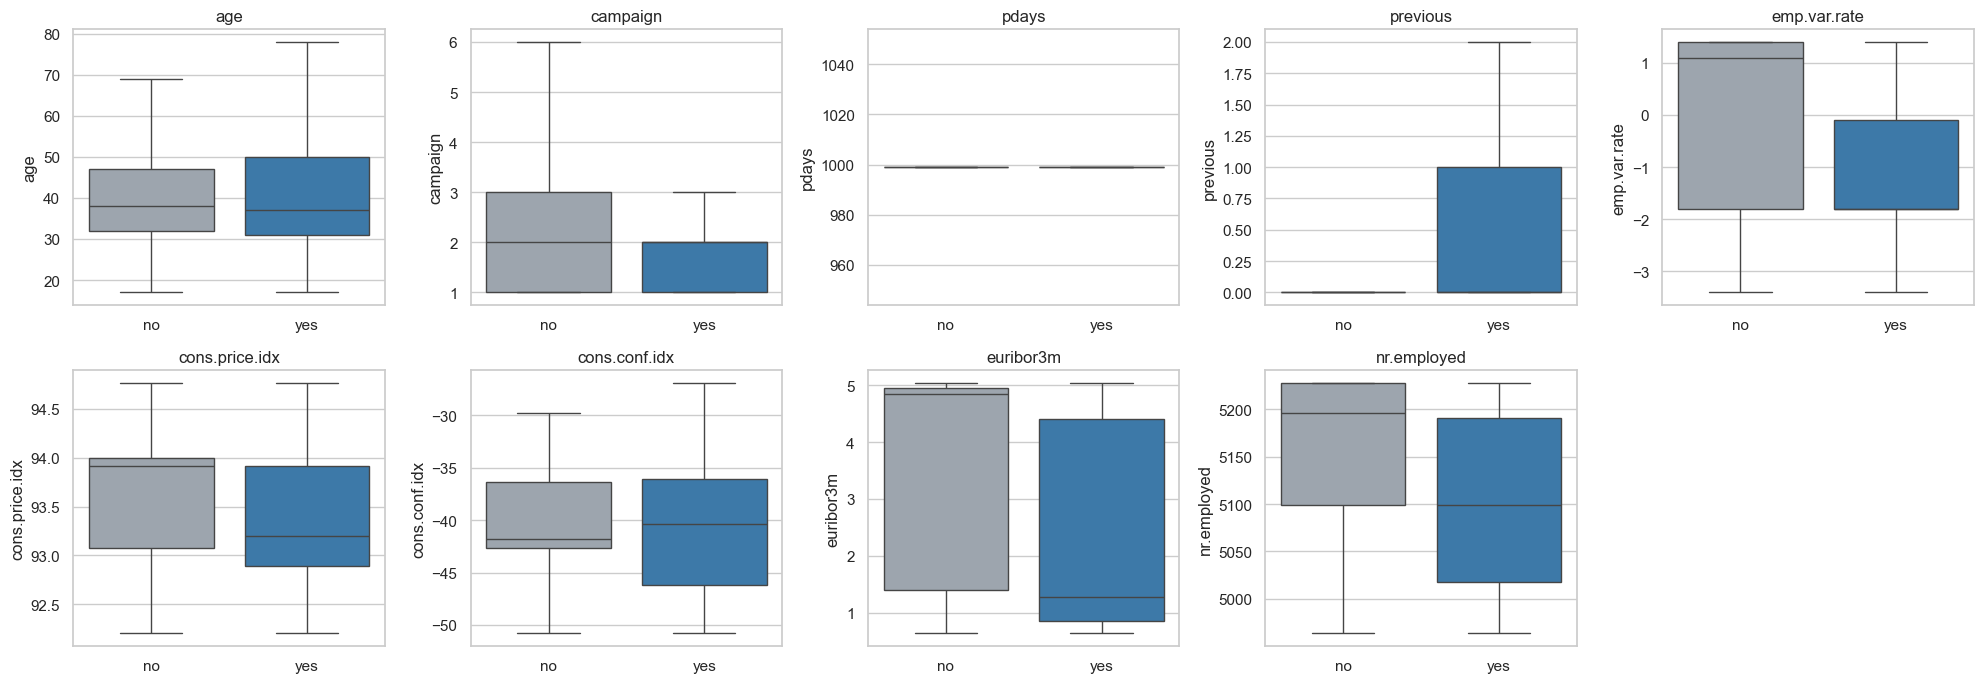

In [16]:
# Boxplots of numeric features by outcome (duration is analysed in 1.14)
plot_cols = [c for c in NUM_COLS if c != "duration"]
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, c in zip(axes.flat, plot_cols):
    sns.boxplot(data=df, x=TARGET, y=c, hue=TARGET, order=["no", "yes"], palette={"no": "#9aa5b1", "yes": "#2b7bba"},
                legend=False, ax=ax, showfliers=False)
    ax.set(title=c, xlabel="")
for ax in axes.flat[len(plot_cols):]:
    ax.axis("off")
save_fig("fig06_numeric_by_target")

**What this shows**
- Apart from `duration` (leakage), the strongest inputs are the **economic indicators** (AUC 0.72–0.75): more clients subscribe when interest rates and employment are low.
- Age looks useless here (AUC 0.511) because its effect is not a straight line.

➡️ **Next:** look at ranges of values.

### 1.10.4 Rates by ranges of values
**What the code does:** groups age, calls, previous contacts and `pdays` into ranges and shows the yes-rate of each range.

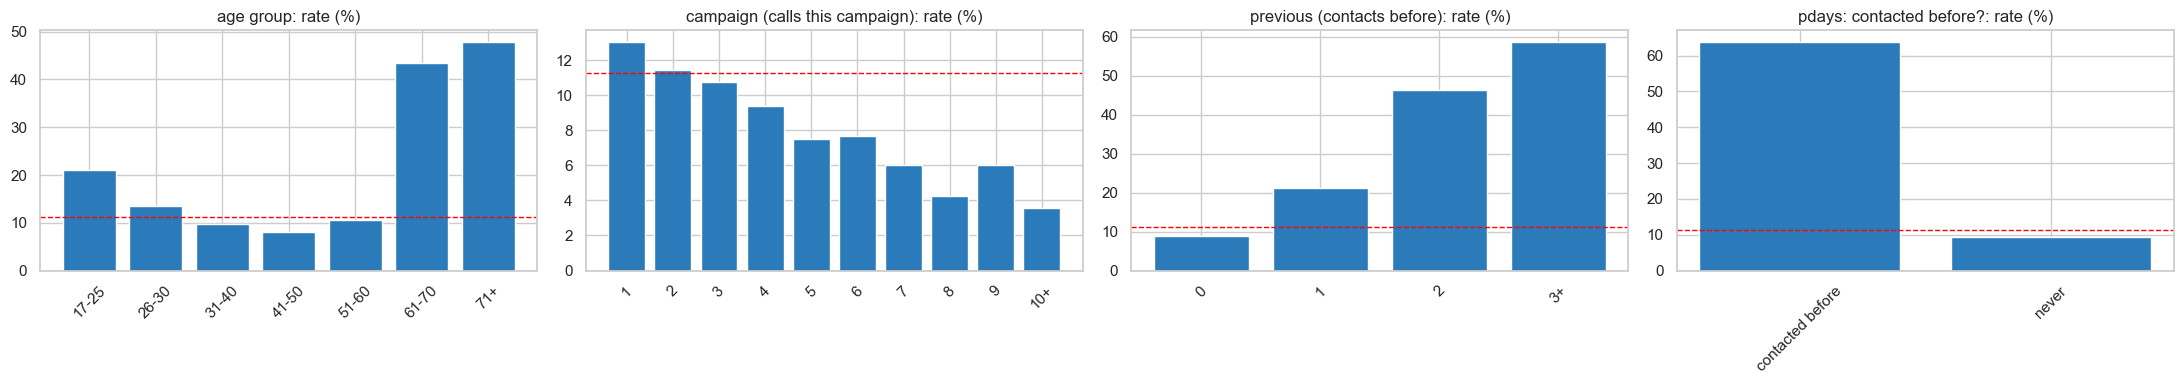


=== age group ===
           n  subscribed   rate  lift_vs_overall
age                                             
17-25   1666         349  20.95             1.86
26-30   5717         775  13.56             1.20
31-40  16385        1597   9.75             0.87
41-50  10240         837   8.17             0.73
51-60   6270         668  10.65             0.95
61-70    488         212  43.44             3.86
71+      422         202  47.87             4.25

=== campaign (calls this campaign) ===
              n  subscribed   rate  lift_vs_overall
campaign                                           
1         17642        2300  13.04             1.16
2         10570        1211  11.46             1.02
3          5341         574  10.75             0.95
4          2651         249   9.39             0.83
5          1599         120   7.50             0.67
6           979          75   7.66             0.68
7           629          38   6.04             0.54
8           400          17   4.

In [17]:
# Group numeric features into ranges to reveal non-linear patterns
age_bins = pd.cut(df["age"], bins=AGE_BINS, labels=AGE_LABELS)
campaign_capped = df["campaign"].clip(upper=10).astype(str).replace({"10": "10+"})
previous_capped = df["previous"].clip(upper=3).astype(str).replace({"3": "3+"})
contacted = np.where(df["pdays"] == PDAYS_NOT_CONTACTED, "never", "contacted before")
binned = {"age group": rate_table(age_bins),
          "campaign (calls this campaign)": rate_table(campaign_capped).reindex([str(i) for i in range(1, 10)] + ["10+"]),
          "previous (contacts before)": rate_table(previous_capped),
          "pdays: contacted before?": rate_table(contacted)}

fig, axes = plt.subplots(1, 4, figsize=(22, 4))
for ax, (name, t) in zip(axes, binned.items()):
    ax.bar(t.index.astype(str), t["rate"], color="#2b7bba")
    ax.axhline(100 * OVERALL_RATE, color="red", ls="--", lw=1)
    ax.set_title(f"{name}: rate (%)")
    ax.tick_params(axis="x", rotation=45)
save_fig("fig07_binned_subscription_rates")
for name, t in binned.items():
    print(f"\n=== {name} ===")
    print(t.to_string())

**What this shows**
- **Age is U-shaped:** young (21%) and older clients (43–48%) respond more than middle-aged clients (8%).
- **Contact fatigue:** 13% at one call → 3.6% at 10+ calls. Clients contacted before → 64% vs 9%.

➡️ **Next:** check data quality.

## 1.11 Data quality
### 1.11.1 `unknown` values
**What the code does:** counts `unknown` values and compares the yes-rate of clients with and without them.

In [18]:
# Count of "unknown" per column and the yes-rate with / without it
rows = []
for c in CAT_COLS:
    is_unk = df[c] == MISSING_TOKEN
    if is_unk.any():
        rows.append({"feature": c, "n_unknown": int(is_unk.sum()), "pct_unknown": round(100 * is_unk.mean(), 2),
                     "rate_if_unknown": round(100 * df.loc[is_unk, "y_num"].mean(), 2),
                     "rate_if_known": round(100 * df.loc[~is_unk, "y_num"].mean(), 2)})
any_unknown = (df[CAT_COLS] == MISSING_TOKEN).any(axis=1)
print(f"Rows with at least one 'unknown': {any_unknown.sum():,} ({any_unknown.mean():.1%})")
print("default value counts:", df["default"].value_counts().to_dict())
pd.DataFrame(rows).set_index("feature").sort_values("n_unknown", ascending=False)

Rows with at least one 'unknown': 10,700 (26.0%)
default value counts: {'no': 32588, 'unknown': 8597, 'yes': 3}


,n_unknown,pct_unknown,rate_if_unknown,rate_if_known
feature,,,,
default,8597,20.87,5.15,12.88
education,1731,4.20,14.50,11.12
housing,990,2.40,10.81,11.28
loan,990,2.40,10.81,11.28
job,330,0.80,11.21,11.27
marital,80,0.19,15.00,11.26


**What the code does:** checks whether `housing` and `loan` are unknown for the same clients.

In [19]:
# Do housing and loan have "unknown" in the same rows?
pd.crosstab(df["housing"], df["loan"])

loan,no,unknown,yes
housing,,,
no,16065,0,2557
unknown,0,990,0
yes,17885,0,3691


**What this shows**
- 26% of rows contain an `unknown`, too many to delete.
- Unknown `default` clients subscribe at 5.2% vs 12.9%, so **`unknown` carries information** and is kept as its own category.

➡️ **Next:** check the `pdays` placeholder.

### 1.11.2 The `pdays` placeholder
**What the code does:** checks whether `pdays`, `previous` and `poutcome` agree with each other.

In [20]:
# Do the three previous-campaign columns agree with each other?
never = df["pdays"] == PDAYS_NOT_CONTACTED
checks = {"pdays = 999 (never contacted)": int(never.sum()), "previous = 0": int((df["previous"] == 0).sum()),
          "poutcome = nonexistent": int((df["poutcome"] == "nonexistent").sum()),
          "pdays = 999 BUT previous > 0": int((never & (df["previous"] > 0)).sum()),
          "pdays != 999 BUT previous = 0": int((~never & (df["previous"] == 0)).sum()),
          "poutcome = nonexistent BUT previous > 0": int(((df["poutcome"] == "nonexistent") & (df["previous"] > 0)).sum())}
print(pd.Series(checks).to_string())
print("\npoutcome where pdays = 999 but previous > 0:", df.loc[never & (df["previous"] > 0), "poutcome"].value_counts().to_dict())

pdays = 999 (never contacted)              39673
previous = 0                               35563
poutcome = nonexistent                     35563
pdays = 999 BUT previous > 0                4110
pdays != 999 BUT previous = 0                  0
poutcome = nonexistent BUT previous > 0        0

poutcome where pdays = 999 but previous > 0: {'failure': 4110}


**What this shows**
- 4,110 rows say "never contacted" (`pdays` = 999) but `previous` > 0, so `pdays` is unreliable.
- `previous` and `poutcome` agree, so a `contacted_before` flag will replace `pdays`.

➡️ **Next:** look for very rare categories.

### 1.11.3 Rare categories
**What the code does:** lists categories with fewer than 0.5% of rows.

In [21]:
# Categories too rare to learn from reliably
rows = []
for c in CAT_COLS:
    vc = df[c].value_counts()
    for cat, n in vc[vc / len(df) < 0.005].items():
        rows.append({"feature": c, "category": cat, "n": n,
                     "subscription_rate": round(100 * df.loc[df[c] == cat, "y_num"].mean(), 2)})
pd.DataFrame(rows)

,feature,category,n,subscription_rate
0,marital,unknown,80,15.00
1,education,illiterate,18,22.22
2,default,yes,3,0.00
3,month,dec,182,48.90


**What this shows**
- `default = yes` (3 rows) and `education = illiterate` (18 rows) are too rare to learn from, so they will be merged.

➡️ **Next:** check correlation between numeric features.

## 1.12 Correlation and multicollinearity
**What the code does:** draws a correlation heatmap and computes the Variance Inflation Factor (VIF > 10 = a feature is almost a copy of others).

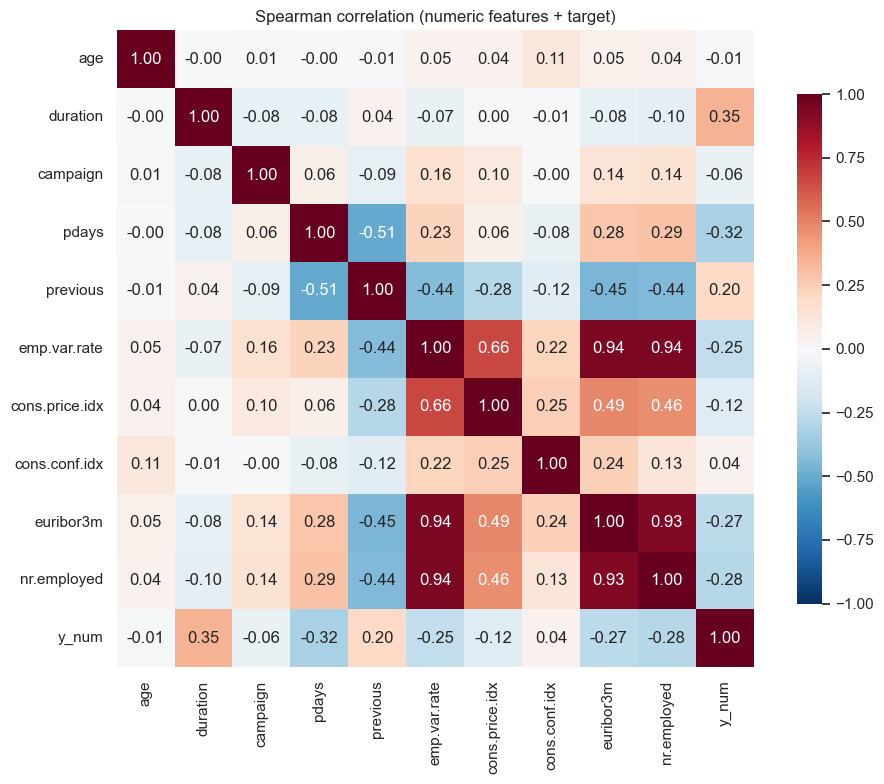

In [22]:
# Correlation heatmap of numeric features and the target
corr = df[NUM_COLS + ["y_num"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title("Spearman correlation (numeric features + target)")
save_fig("fig08_correlation_heatmap")

**What the code does:** computes VIF for the numeric inputs.

In [23]:
# VIF of numeric inputs (without duration and the pdays placeholder)
vif_table(df[[c for c in NUM_COLS if c not in ("duration", "pdays")]]).sort_values("VIF", ascending=False)

,VIF
feature,
euribor3m,64.3
emp.var.rate,33.1
nr.employed,31.6
cons.price.idx,6.3
cons.conf.idx,2.6
previous,1.3
age,1.0
campaign,1.0


**What this shows**
- `euribor3m`, `emp.var.rate` and `nr.employed` carry almost the same information (VIF 64.3 / 33.1 / 31.6).
- This would confuse Logistic Regression, so it will keep only one of them (Part 2). Tree models are not affected.

➡️ **Next:** look at changes over time.

## 1.13 Time pattern
**What the code does:** plots the monthly yes-rate and the Euribor interest rate in date order, and the yes-rate per year.

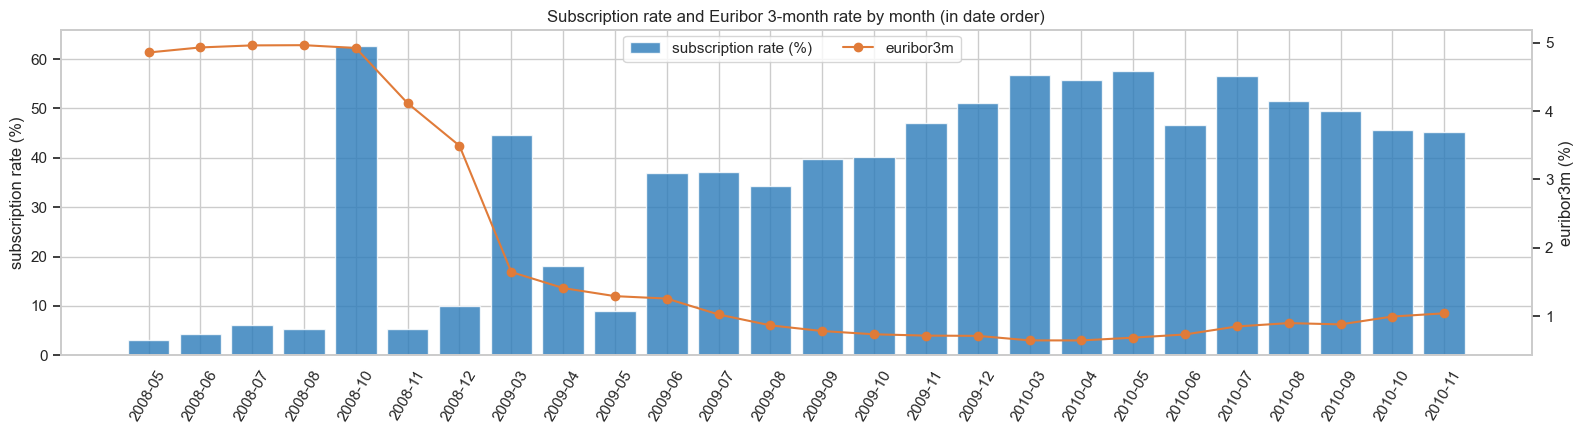

,n,rate
eda_year,,
2008,27690,4.84
2009,11440,19.48
2010,2058,52.14


In [24]:
# Subscription rate and Euribor rate month by month, in date order
by_period = (df.groupby("eda_period", sort=False)
             .agg(n=("y_num", "size"), rate=("y_num", "mean"), euribor3m=("euribor3m", "mean"))
             .assign(rate=lambda t: (100 * t["rate"]).round(2)))
fig, ax1 = plt.subplots(figsize=(16, 4.5))
ax1.bar(by_period.index, by_period["rate"], color="#2b7bba", alpha=0.8, label="subscription rate (%)")
ax1.set_ylabel("subscription rate (%)")
ax1.tick_params(axis="x", rotation=60)
ax2 = ax1.twinx()
ax2.plot(by_period.index, by_period["euribor3m"], color="#e07b39", marker="o", label="euribor3m")
ax2.set_ylabel("euribor3m (%)")
ax2.grid(False)
ax1.set_title("Subscription rate and Euribor 3-month rate by month (in date order)")
fig.legend(loc="upper center", bbox_to_anchor=(0.5, 0.92), ncol=2)
save_fig("fig09_time_pattern")

# Yes-rate per year
rate_by_year = df.groupby("eda_year")["y_num"].agg(n="size", rate="mean")
rate_by_year["rate"] = (100 * rate_by_year["rate"]).round(2)
rate_by_year

**What this shows**
- The yes-rate rose from **4.8% (2008) to 19.5% (2009) to 52.1% (2010)** as interest rates fell.
- So results from a random split may be optimistic for future campaigns; this is checked in Part 3.

➡️ **Next:** confirm the `duration` leakage.

## 1.14 Leakage check: `duration`
**What the code does:** measures how strongly call length alone predicts the outcome.

Single-feature ROC-AUC of duration: 0.818 | best other input: 0.749 (nr.employed)
Calls with duration = 0: 4, subscribed: 0


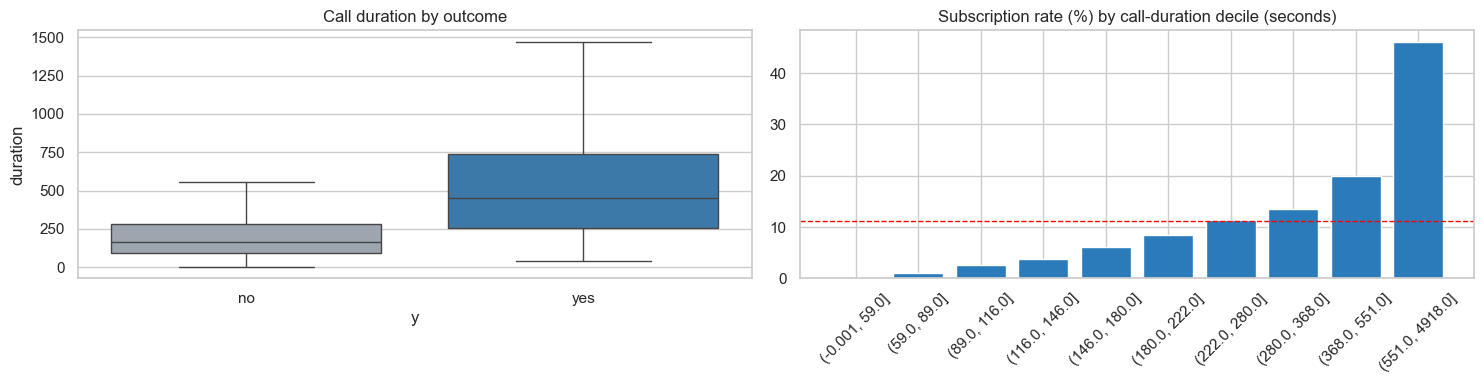

,n,subscribed,rate,lift_vs_overall
duration,,,,
"(-0.001, 59.0]",4181,1,0.02,0.00
"(59.0, 89.0]",4207,43,1.02,0.09
"(89.0, 116.0]",3987,107,2.68,0.24
"(116.0, 146.0]",4152,157,3.78,0.34
"(146.0, 180.0]",4178,256,6.13,0.54
"(180.0, 222.0]",4096,346,8.45,0.75
"(222.0, 280.0]",4062,463,11.40,1.01
"(280.0, 368.0]",4103,554,13.50,1.20
"(368.0, 551.0]",4118,824,20.01,1.78


In [25]:
# How strongly call duration alone predicts the outcome
auc_duration = roc_auc_score(df["y_num"], df["duration"])
other = assoc_num.drop(index="duration")["auc_strength"]
print(f"Single-feature ROC-AUC of duration: {auc_duration:.3f} | best other input: {other.max():.3f} ({other.idxmax()})")
print(f"Calls with duration = 0: {(df['duration'] == 0).sum()}, subscribed: {df.loc[df['duration'] == 0, 'y_num'].sum()}")

# Yes-rate by call-duration decile
dur_rates = rate_table(pd.qcut(df["duration"], q=10, duplicates="drop"))
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.boxplot(data=df, x=TARGET, y="duration", hue=TARGET, order=["no", "yes"], palette={"no": "#9aa5b1", "yes": "#2b7bba"},
            legend=False, showfliers=False, ax=axes[0])
axes[0].set_title("Call duration by outcome")
axes[1].bar(dur_rates.index.astype(str), dur_rates["rate"], color="#2b7bba")
axes[1].axhline(100 * OVERALL_RATE, color="red", ls="--", lw=1)
axes[1].set_title("Subscription rate (%) by call-duration decile (seconds)")
axes[1].tick_params(axis="x", rotation=45)
save_fig("fig10_duration_leakage")
dur_rates

**What this shows**
- `duration` alone reaches AUC 0.818, better than any information available before a call, and the longest calls have 46% yes vs 0.02% for the shortest.
- It describes the outcome rather than predicting it, so it is removed.

## Part 1 summary
- **Target imbalance (11.27% yes)** → use PR-AUC, not accuracy; handle imbalance in Part 2.
- **Data issues** → remove 12 duplicates and `duration`; keep `unknown`; replace `pdays`; keep outliers but cap `campaign`; merge rare levels.
- **Signals** → previous success, economy, month, mobile contact, students/retired, U-shaped age, contact fatigue.
- **Risks** → collinear economic indicators and strong change over time.

# Part 2 – Preprocessing and Feature Engineering
**Owner:** Jayasuriya J.A.Y.N

**Goal:** turn the raw data into clean, leakage-free inputs. **What we do:** (1) apply fixed cleaning rules, (2) split train/test,
(3) choose features, (4) build two pipelines, (5) decide how to handle imbalance. **Key rule:** anything that *learns* from data
(encoding, scaling) is fitted on **training data only**, inside a pipeline.

## 2.1 Row-level cleaning
**What the code does:** applies each cleaning rule one by one and prints its effect: (a) remove duplicates, (b) remove `duration`, (c) add `contacted_before` and drop `pdays`, (d) merge `default`, (e) merge `illiterate`, (f) cap `campaign` at 10, (g) code the target as 1/0. Finally it checks the result equals `clean_rows(raw)`.

In [26]:
# (a) Remove exact duplicates (D8)
step = raw.drop_duplicates().reset_index(drop=True)
print(f"(a) Rows: {len(raw):,} -> {len(step):,} | yes-rate {(raw[TARGET] == 'yes').mean():.4%} -> {(step[TARGET] == 'yes').mean():.4%}")

# (b) Remove duration: only known after the call (D3)
step = step.drop(columns=LEAKAGE_FEATURES)

# (c) Replace pdays with a "contacted before" flag based on previous (D10)
step["contacted_before"] = (step["previous"] > 0).astype(int)
print("(c) contacted_before vs poutcome:")
display(pd.crosstab(step["contacted_before"], step["poutcome"]))
print("    yes-rate % by contacted_before:", step.groupby("contacted_before")[TARGET].apply(lambda s: round(100 * (s == 'yes').mean(), 2)).to_dict())
step = step.drop(columns=["pdays"])

# (d) default: merge the 3 "yes" rows into "not_no" (D13)
print("(d) default before:", step["default"].value_counts().to_dict())
step["default"] = np.where(step["default"] == "no", "no", "not_no")
print("    default after: ", step["default"].value_counts().to_dict())

# (e) education: merge the rare "illiterate" level into "basic.4y" (D14)
print("(e) illiterate rows:", (step["education"] == "illiterate").sum())
step["education"] = step["education"].replace(EDUCATION_MERGE)

# (f) Cap campaign at 10 calls (D9)
capped = step["campaign"] > CAMPAIGN_CAP
print(f"(f) campaign rows capped: {capped.sum()} ({capped.mean():.2%}); their yes-rate {(step.loc[capped, TARGET] == 'yes').mean():.2%}")
step["campaign"] = step["campaign"].clip(upper=CAMPAIGN_CAP)

# (g) Target: yes -> 1, no -> 0
step[TARGET] = (step[TARGET] == POSITIVE_CLASS).astype(int)

# The step-by-step result must equal the helper function used everywhere else
clean = clean_rows(raw)
pd.testing.assert_frame_equal(step, clean)
print(f"Step-by-step result == clean_rows(raw); clean data: {clean.shape}")

(a) Rows: 41,188 -> 41,176 | yes-rate 11.2654% -> 11.2663%
(c) contacted_before vs poutcome:


poutcome,failure,nonexistent,success
contacted_before,,,
0,0,35551,0
1,4252,0,1373


    yes-rate % by contacted_before: {0: 8.83, 1: 26.65}
(d) default before: {'no': 32577, 'unknown': 8596, 'yes': 3}
    default after:  {'no': 32577, 'not_no': 8599}
(e) illiterate rows: 18
(f) campaign rows capped: 869 (2.11%); their yes-rate 3.11%
Step-by-step result == clean_rows(raw); clean data: (41176, 20)


**What this shows**
- 41,188 → **41,176 rows**; yes-rate unchanged.
- `contacted_before` matches `poutcome` exactly; 869 rows were capped at 10 calls.

➡️ **Next:** split into training and test sets.

## 2.2 Train/test split
**What the code does:** splits the clean data 80/20, **stratified** so both parts keep the 11.27% yes-rate (seed 42). The test set is now locked until Part 5.

In [27]:
# Stratified 80/20 split (row positions are kept as the index, which is also the date order)
X = clean.drop(columns=TARGET)
y = clean[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
pd.DataFrame({"rows": [len(y_train), len(y_test)], "yes": [y_train.sum(), y_test.sum()],
              "yes_rate_%": [round(100 * y_train.mean(), 2), round(100 * y_test.mean(), 2)]}, index=["train", "test"])

,rows,yes,yes_rate_%
train,32940,3711,11.27
test,8236,928,11.27


**What this shows**
- Train 32,940 rows, test 8,236 rows, both exactly 11.27% yes.

➡️ **Next:** choose features using the training set only.

## 2.3 Feature selection (training data only)
**What the code does:** (1) runs the chi-square test on the training set for `housing`, `loan` and `day_of_week`.

In [28]:
# 1. Chi-square test on the training set (poutcome shown for comparison)
chi_train = chi_square_table(X_train, ["housing", "loan", "day_of_week", "poutcome"], y_train)
chi_train.assign(p_value=chi_train["p_value"].round(4))

,chi2,dof,p_value
feature,,,
poutcome,3472.0,2,0.0000
day_of_week,10.7,4,0.0307
housing,2.7,2,0.2599
loan,0.2,2,0.9218


**What the code does:** (2) compares quick, untuned Logistic Regression and Random Forest models with three feature sets using 5-fold CV.

In [29]:
# 2. Quick untuned models compared on three feature sets, same 5 folds
feature_sets = {"all features": [], "drop housing + loan": ["housing", "loan"],
                "drop housing + loan + day_of_week": ["housing", "loan", "day_of_week"]}
quick = {"LogReg": ("linear", LogisticRegression(class_weight="balanced", max_iter=2000)),
         "RandomForest": ("tree", RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced_subsample",
                                                          n_jobs=-1, random_state=RANDOM_STATE))}
rows = []
for model_name, (kind, model) in quick.items():
    for set_name, drop in feature_sets.items():
        pipe = Pipeline([("prep", build_preprocessor(kind, drop=drop)), ("model", model)])
        s = cross_validate(pipe, X_train, y_train, cv=CV, scoring=["average_precision", "roc_auc"])
        rows.append({"model": model_name, "feature set": set_name,
                     "PR-AUC mean": s["test_average_precision"].mean(), "PR-AUC std": s["test_average_precision"].std(),
                     "ROC-AUC mean": s["test_roc_auc"].mean(), "ROC-AUC std": s["test_roc_auc"].std()})
pd.DataFrame(rows).round(4)

,model,feature set,PR-AUC mean,PR-AUC std,ROC-AUC mean,ROC-AUC std
0,LogReg,all features,0.4365,0.0126,0.7876,0.0072
1,LogReg,drop housing + loan,0.4368,0.0131,0.7878,0.0071
2,LogReg,drop housing + loan + day_of_week,0.4351,0.0127,0.7881,0.0081
3,RandomForest,all features,0.4641,0.0159,0.7941,0.0073
4,RandomForest,drop housing + loan,0.4646,0.0180,0.7958,0.0093
5,RandomForest,drop housing + loan + day_of_week,0.4593,0.0159,0.7935,0.0078


**What this shows**
- `housing` and `loan` are not related to the target (p = 0.26 and 0.92), and removing them changes PR-AUC by less than 0.001 → **dropped**.
- Removing `day_of_week` lowers PR-AUC in both models → **kept**.

➡️ **Next:** fix the correlated economic indicators for Logistic Regression.

## 2.4 Collinearity fix for Logistic Regression
**What the code does:** compares the three correlated indicators and recomputes VIF with only `euribor3m` kept.

In [30]:
# Single-feature strength of the three collinear indicators (training data)
def auc_strength(feature):
    auc = roc_auc_score(y_train, X_train[feature])
    return round(max(auc, 1 - auc), 3)
print("Single-feature AUC on training data:", {c: auc_strength(c) for c in ["euribor3m", "emp.var.rate", "nr.employed"]})

# VIF before (all numeric inputs) and after (linear-model inputs)
_, nums_tree = feature_lists("tree")
_, nums_linear = feature_lists("linear")
vif_compare = vif_table(X_train[nums_tree]).rename(columns={"VIF": "VIF before (all numerics)"}).join(
    vif_table(X_train[nums_linear]).rename(columns={"VIF": "VIF after (linear set)"}), how="left")
vif_compare.fillna("removed")

Single-feature AUC on training data: {'euribor3m': 0.74, 'emp.var.rate': 0.713, 'nr.employed': 0.745}


,VIF before (all numerics),VIF after (linear set)
feature,,
age,1.0,removed
campaign,1.0,1.0
previous,4.8,4.7
contacted_before,4.7,4.7
emp.var.rate,33.5,removed
cons.price.idx,6.3,2.1
cons.conf.idx,2.6,1.2
euribor3m,64.6,2.7
nr.employed,31.7,removed


**What this shows**
- Keeping only `euribor3m` lowers the highest VIF from **64.6 to 4.7**.

➡️ **Next:** build the preprocessing pipelines.

## 2.5 The two preprocessing pipelines
**What the code does:** builds each pipeline, fits it on the training data and checks the output (number of columns, no missing values, scaling).

| | Linear pipeline (Logistic Regression) | Tree pipeline (DT, RF, XGBoost) |
|---|---|---|
| Categories | One-hot encoding | One-hot encoding |
| Age | Age groups (captures the U-shape) | Raw age |
| Numbers | Scaled (mean 0, std 1) | Not scaled (trees don't need it) |
| Economic indicators | `euribor3m` + 2 others | All five |

In [31]:
# Fit each preprocessor on TRAIN only and inspect the output
for kind in ["linear", "tree"]:
    pre = build_preprocessor(kind)
    Xt_train, Xt_test = pre.fit_transform(X_train), pre.transform(X_test)
    print(f"{kind:6s}: {Xt_train.shape[1]} output columns | train {Xt_train.shape} | test {Xt_test.shape} | "
          f"missing values: {np.isnan(Xt_train).any() or np.isnan(Xt_test).any()}")

# Scaled numeric columns of the linear pipeline should have mean 0 and std 1 on TRAIN
pre_lin = build_preprocessor("linear").fit(X_train)
Xt = pd.DataFrame(pre_lin.transform(X_train), columns=pre_lin.get_feature_names_out())
Xt[nums_linear].describe().loc[["mean", "std"]].round(3)

linear: 58 output columns | train (32940, 58) | test (8236, 58) | missing values: False
tree  : 54 output columns | train (32940, 54) | test (8236, 54) | missing values: False


,campaign,previous,contacted_before,euribor3m,cons.price.idx,cons.conf.idx
mean,0.0,0.0,-0.0,-0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0


**What this shows**
- Linear pipeline: 58 columns; tree pipeline: 54 columns; no missing values.

➡️ **Next:** decide how to handle class imbalance.

## 2.6 Class imbalance
The data is 7.9 : 1 (no : yes). Options were: do nothing, undersample, SMOTE (synthetic clients), **class weights**, or threshold tuning. We use **class weights** (mistakes on "yes" cost more) because they change no data and work for all four models; SMOTE is tested in Part 4 and thresholds are tuned in Part 5.

**What the code does:** computes the class weights and XGBoost's `scale_pos_weight` from the training set.

In [32]:
# Class weights and XGBoost scale_pos_weight computed from the training set
weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
SCALE_POS_WEIGHT = (y_train == 0).sum() / (y_train == 1).sum()
print("Training counts:", y_train.value_counts().to_dict())
print(f"class_weight='balanced' -> no: {weights[0]:.3f}, yes: {weights[1]:.3f} | XGBoost scale_pos_weight = {SCALE_POS_WEIGHT:.2f}")

Training counts: {0: 29229, 1: 3711}
class_weight='balanced' -> no: 0.563, yes: 4.438 | XGBoost scale_pos_weight = 7.88


**What this shows**
- Weights: no = 0.563, yes = 4.438 (a missed subscriber costs about 7.9× more). XGBoost `scale_pos_weight` = 7.88.

## Part 2 summary
- Clean data: 41,176 rows; leakage (`duration`) removed; `unknown` kept; `pdays` replaced; rare levels merged; `campaign` capped.
- Stratified split before any data-driven decision (train 32,940 / test 8,236).
- Features: `housing` and `loan` dropped; Logistic Regression keeps one economic indicator.
- Imbalance: class weights.

# Part 3 – Validation Design
**Owner:** Thennakoon T.M.S.D

**Goal:** decide how models are judged *before* building them. **What we do:** fix the cross-validation folds and metrics, measure the
minimum score to beat, prove the `duration` leakage with numbers, and check how results change over time. Only the training set is used.

| Metric | Meaning | Role |
|---|---|---|
| **PR-AUC** | How well "yes" clients are ranked at the top (random ≈ 0.11) | **Main metric** |
| ROC-AUC | Ranking quality over both classes (random = 0.5) | Secondary |
| Recall / precision / F1 | Subscribers found / calls that succeed / balance | Business view |
| **Top-20% capture** | Share of subscribers reached by calling the top 20% (random = 20%) | **Business metric** |
| Accuracy | Share of correct predictions | Shown only to prove it is misleading |

## 3.1 Cross-validation folds
**What the code does:** shows the size and yes-rate of the 5 stratified folds used by every model.

In [33]:
# Size and yes-rate of each validation fold
rows = [{"fold": i, "train_rows": len(tr), "val_rows": len(va), "val_yes": int(y_train.iloc[va].sum()),
         "val_yes_rate_%": round(100 * y_train.iloc[va].mean(), 2)}
        for i, (tr, va) in enumerate(CV.split(X_train, y_train), start=1)]
pd.DataFrame(rows).set_index("fold")

,train_rows,val_rows,val_yes,val_yes_rate_%
fold,,,,
1,26352,6588,742,11.26
2,26352,6588,742,11.26
3,26352,6588,742,11.26
4,26352,6588,742,11.26
5,26352,6588,743,11.28


**What this shows**
- Each fold has 6,588 validation rows with about 742 subscribers, so all models are compared on equal folds.

➡️ **Next:** measure the minimum score to beat.

## 3.2 Reference floor
**What the code does:** evaluates two dummy models (always "no", random guess) and two quick untuned models with all metrics.

In [34]:
def quick_models():
    # The untuned Logistic Regression and Random Forest from section 2.3
    return {"LogReg (untuned)": Pipeline([("prep", build_preprocessor("linear")),
                                          ("model", LogisticRegression(class_weight="balanced", max_iter=2000))]),
            "RandomForest (untuned)": Pipeline([("prep", build_preprocessor("tree")),
                                                ("model", RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                                                                 class_weight="balanced_subsample",
                                                                                 n_jobs=-1, random_state=RANDOM_STATE))])}

# Dummy models and quick models through the same evaluation
reference = {"Dummy: always no": Pipeline([("prep", build_preprocessor("tree")), ("model", DummyClassifier(strategy="most_frequent"))]),
             "Dummy: random guess": Pipeline([("prep", build_preprocessor("tree")),
                                              ("model", DummyClassifier(strategy="stratified", random_state=RANDOM_STATE))]),
             **quick_models()}
ref_rows = [evaluate_cv(model, X_train, y_train, name) for name, model in reference.items()]
cv_table(ref_rows)

,pr_auc,roc_auc,recall,precision,f1,balanced_acc,accuracy,top20_capture
model,,,,,,,,
Dummy: always no,0.113 ± 0.000,0.500 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.887 ± 0.000,0.189 ± 0.005
Dummy: random guess,0.113 ± 0.001,0.502 ± 0.004,0.114 ± 0.006,0.115 ± 0.006,0.115 ± 0.006,0.502 ± 0.004,0.802 ± 0.001,0.199 ± 0.009
LogReg (untuned),0.437 ± 0.013,0.788 ± 0.007,0.625 ± 0.014,0.339 ± 0.010,0.440 ± 0.011,0.735 ± 0.008,0.820 ± 0.005,0.620 ± 0.014
RandomForest (untuned),0.465 ± 0.018,0.796 ± 0.009,0.590 ± 0.017,0.426 ± 0.015,0.495 ± 0.014,0.744 ± 0.009,0.864 ± 0.005,0.637 ± 0.013


**What this shows**
- "Always no" has the **highest accuracy (0.887) but recall 0**, which proves accuracy is the wrong metric.
- Real models must beat PR-AUC 0.113; even untuned models reach 0.44–0.47.

➡️ **Next:** measure what `duration` would have done.

## 3.3 Leakage benchmark
**What the code does:** runs the untuned models with and without `duration` (training data only).

In [35]:
# Training rows plus their call duration
raw_dedup = raw.drop_duplicates().reset_index(drop=True)
Xd = X_train.assign(duration=raw_dedup.loc[X_train.index, "duration"].to_numpy())

def with_duration(kind, model):
    # Same preprocessing as the realistic model, plus a scaled duration column
    pre = ColumnTransformer([("base", build_preprocessor(kind), list(X_train.columns)),
                             ("duration", StandardScaler(), ["duration"])])
    return Pipeline([("prep", pre), ("model", model)])

qm = quick_models()
leak_models = {"LogReg WITHOUT duration": qm["LogReg (untuned)"],
               "LogReg WITH duration": with_duration("linear", clone(qm["LogReg (untuned)"].named_steps["model"])),
               "RandomForest WITHOUT duration": qm["RandomForest (untuned)"],
               "RandomForest WITH duration": with_duration("tree", clone(qm["RandomForest (untuned)"].named_steps["model"]))}
leak_rows = [evaluate_cv(m, Xd, y_train, name) for name, m in leak_models.items()]
cv_table(leak_rows, metrics=("pr_auc", "roc_auc", "recall", "precision", "f1", "top20_capture"))

,pr_auc,roc_auc,recall,precision,f1,top20_capture
model,,,,,,
LogReg WITHOUT duration,0.437 ± 0.013,0.788 ± 0.007,0.625 ± 0.014,0.339 ± 0.010,0.440 ± 0.011,0.620 ± 0.014
LogReg WITH duration,0.584 ± 0.015,0.935 ± 0.003,0.880 ± 0.006,0.441 ± 0.009,0.588 ± 0.008,0.842 ± 0.010
RandomForest WITHOUT duration,0.465 ± 0.018,0.796 ± 0.009,0.590 ± 0.017,0.426 ± 0.015,0.495 ± 0.014,0.637 ± 0.013
RandomForest WITH duration,0.656 ± 0.016,0.946 ± 0.002,0.871 ± 0.005,0.492 ± 0.010,0.629 ± 0.008,0.874 ± 0.007


**What this shows**
- With `duration`, PR-AUC would jump to 0.58–0.66 — impressive, but impossible before a call. This confirms removing it.

➡️ **Next:** check change over time.

## 3.4 Time-drift check
Shuffled CV mixes all years; a real campaign uses the past to predict the future. **Forward-in-time CV** trains on earlier rows and validates on later rows.

**What the code does:** puts training rows in date order and runs 5 forward-in-time folds.

In [36]:
# Year of every row (analysis only) and the training rows in date order
year = reconstruct_year(clean["month"])
train_ordered = X_train.assign(**{TARGET: y_train, "year": year.loc[X_train.index]}).sort_index()
print("Training rows per year:")
print(train_ordered.groupby("year")[TARGET].agg(rows="size", yes_rate=lambda s: round(100 * s.mean(), 2)).to_string())

# Forward-in-time validation: train on earlier rows, validate on the next block
Xo, yo = train_ordered[list(X_train.columns)], train_ordered[TARGET]
rows = []
for name, model in quick_models().items():
    for fold, (tr, va) in enumerate(TimeSeriesSplit(n_splits=5).split(Xo), start=1):
        m = clone(model).fit(Xo.iloc[tr], yo.iloc[tr])
        s = score_predictions(yo.iloc[va], m.predict_proba(Xo.iloc[va])[:, 1])
        val_years = train_ordered["year"].iloc[va]
        rows.append({"model": name, "fold": fold, "train_rows": len(tr),
                     "val_period": f"{val_years.min()}-{val_years.max()}" if val_years.nunique() > 1 else str(val_years.iloc[0]),
                     "val_yes_rate_%": round(100 * yo.iloc[va].mean(), 2), "roc_auc": round(s["roc_auc"], 3),
                     "pr_auc": round(s["pr_auc"], 3), "pr_auc_lift": round(s["pr_auc"] / yo.iloc[va].mean(), 2),
                     "top20_capture": round(s["top20_capture"], 3)})
time_folds = pd.DataFrame(rows)
time_folds

Training rows per year:
       rows  yes_rate
year                 
2008  22116      4.92
2009   9159     19.19
2010   1665     51.89


,model,fold,train_rows,val_period,val_yes_rate_%,roc_auc,pr_auc,pr_auc_lift,top20_capture
0,LogReg (untuned),1,5490,2008,4.74,0.520,0.049,1.03,0.208
1,LogReg (untuned),2,10980,2008,6.54,0.526,0.070,1.07,0.206
2,LogReg (untuned),3,16470,2008,5.57,0.439,0.052,0.93,0.180
3,LogReg (untuned),4,21960,2008-2009,12.68,0.667,0.204,1.61,0.375
4,LogReg (untuned),5,27450,2009-2010,35.17,0.421,0.313,0.89,0.105
5,RandomForest (untuned),1,5490,2008,4.74,0.513,0.049,1.03,0.212
6,RandomForest (untuned),2,10980,2008,6.54,0.504,0.075,1.15,0.198
7,RandomForest (untuned),3,16470,2008,5.57,0.415,0.045,0.82,0.154
8,RandomForest (untuned),4,21960,2008-2009,12.68,0.623,0.193,1.52,0.330
9,RandomForest (untuned),5,27450,2009-2010,35.17,0.696,0.528,1.50,0.337


**What the code does:** compares shuffled and forward-in-time results and shows why later blocks are hard (unseen months, different interest rates, contact history per year).

In [37]:
# Shuffled CV (3.2) vs forward-in-time CV
shuffled = pd.DataFrame(ref_rows).set_index("model")
drift_compare = pd.DataFrame([{
    "model": name,
    "ROC-AUC shuffled CV": round(shuffled.loc[name, "roc_auc_mean"], 3),
    "ROC-AUC forward (mean)": round(time_folds.loc[time_folds["model"] == name, "roc_auc"].mean(), 3),
    "ROC-AUC forward (min)": round(time_folds.loc[time_folds["model"] == name, "roc_auc"].min(), 3),
    "PR-AUC lift shuffled": round(shuffled.loc[name, "pr_auc_mean"] / y_train.mean(), 2),
    "PR-AUC lift forward (mean)": round(time_folds.loc[time_folds["model"] == name, "pr_auc_lift"].mean(), 2),
} for name in quick_models()]).set_index("model")

# Why the forward folds are hard: prior-contact history and Euribor range per validation block
blocks = []
for fold, (tr, va) in enumerate(TimeSeriesSplit(n_splits=5).split(Xo), start=1):
    blocks.append({"fold": fold, "val months unseen in training": sorted(set(Xo["month"].iloc[va]) - set(Xo["month"].iloc[tr])),
                   "train euribor range": f"{Xo['euribor3m'].iloc[tr].min():.2f}-{Xo['euribor3m'].iloc[tr].max():.2f}",
                   "val euribor range": f"{Xo['euribor3m'].iloc[va].min():.2f}-{Xo['euribor3m'].iloc[va].max():.2f}",
                   "val contacted_before %": round(100 * Xo["contacted_before"].iloc[va].mean(), 1)})
print("Contacted before, % of clients per year:",
      (100 * clean.groupby(year)["contacted_before"].mean()).round(1).to_dict())
display(pd.DataFrame(blocks).set_index("fold"))
drift_compare

Contacted before, % of clients per year: {2008: 2.7, 2009: 32.1, 2010: 59.0}


,val months unseen in training,train euribor range,val euribor range,val contacted_before %
fold,,,,
1,"[jul, jun]",4.86-4.86,4.86-4.97,0.0
2,[aug],4.86-4.97,4.96-4.97,0.0
3,"[nov, oct]",4.86-4.97,4.02-5.04,9.9
4,"[apr, dec, mar]",4.02-5.04,1.27-4.02,30.0
5,[sep],1.27-5.04,0.63-1.29,42.2


,ROC-AUC shuffled CV,ROC-AUC forward (mean),ROC-AUC forward (min),PR-AUC lift shuffled,PR-AUC lift forward (mean)
model,,,,,
LogReg (untuned),0.788,0.515,0.421,3.88,1.11
RandomForest (untuned),0.796,0.550,0.415,4.12,1.20


**What the code does:** plots forward-in-time ROC-AUC per fold against the shuffled-CV average.

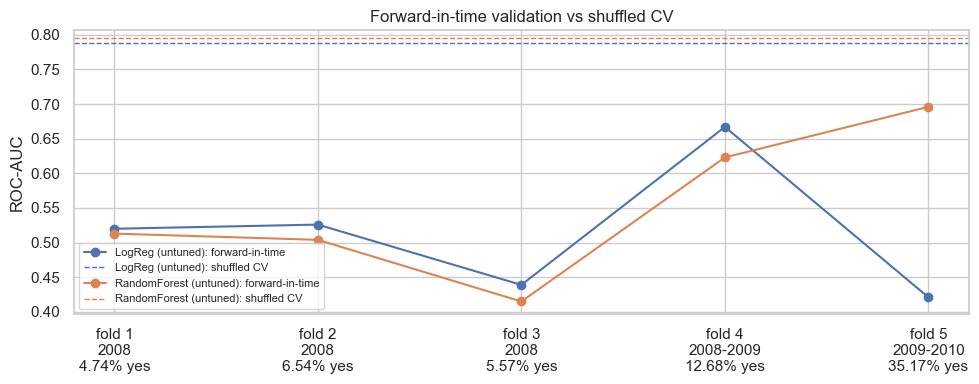

In [38]:
# Forward-in-time ROC-AUC per fold vs the shuffled-CV mean
fig, ax = plt.subplots(figsize=(10, 4))
for name, grp in time_folds.groupby("model"):
    ax.plot(grp["fold"], grp["roc_auc"], marker="o", label=f"{name}: forward-in-time")
    ax.axhline(shuffled.loc[name, "roc_auc_mean"], ls="--", lw=1, color=ax.lines[-1].get_color(), label=f"{name}: shuffled CV")
labels = time_folds.drop_duplicates("fold").set_index("fold")
ax.set_xticks(labels.index)
ax.set_xticklabels([f"fold {f}\n{labels.loc[f, 'val_period']}\n{labels.loc[f, 'val_yes_rate_%']}% yes" for f in labels.index])
ax.set(ylabel="ROC-AUC", title="Forward-in-time validation vs shuffled CV")
ax.legend(fontsize=8, loc="lower left")
save_fig("fig11_time_drift_validation")

**What this shows**
- Trained on the past and tested on the future, the models are close to random (ROC-AUC 0.52–0.55 vs about 0.79 with shuffled CV).
- Reasons: almost no contact history in 2008, months never seen in training, and much lower interest rates later.
- We keep shuffled CV to compare models, and report this as a key limitation (retrain regularly).

## Part 3 summary
- 5-fold stratified CV, same folds for all models; **PR-AUC** main metric, **top-20% capture** business metric.
- Floor: PR-AUC 0.113; accuracy is misleading.
- `duration` leakage confirmed; strong time drift found.

# Part 4 – Modelling
**Owners:** one model per member (see each section)

**Goal:** build and tune four models on the training set and compare them fairly. Each model is a full pipeline (preprocessing + model),
tuned with the same 5 folds and scored by PR-AUC, using class weights.

| Model | Role | Owner |
|---|---|---|
| Logistic Regression | Baseline | Karunathilaka S.H.T.R |
| Decision Tree | Alternative 1 | Jayasuriya J.A.Y.N |
| Random Forest | Alternative 2 | Thulmanthi W.A.S |
| XGBoost | Alternative 3 | Thennakoon T.M.S.D |

**What the code does:** defines two small functions: `run_search` (runs a hyperparameter search and prints the best result) and `top_results` (shows the best settings).

In [39]:
searches = {}   # fitted searches, one per model

def run_search(name, search):
    # Fit a hyperparameter search on the training set and print the best result
    start = time.time()
    search.fit(X_train, y_train)
    searches[name] = search
    i = search.best_index_
    print(f"{name}: {len(search.cv_results_['params'])} settings x {search.n_splits_} folds in {time.time() - start:.0f}s")
    print(f"  best CV PR-AUC = {search.cv_results_['mean_test_score'][i]:.4f} ± {search.cv_results_['std_test_score'][i]:.4f}")
    print(f"  best params    = {search.best_params_}")

def top_results(search, n=5):
    # The n best settings: parameters, CV score and training score
    res = pd.DataFrame(search.cv_results_)
    return (res[["params", "mean_test_score", "std_test_score", "mean_train_score", "rank_test_score"]]
            .sort_values("rank_test_score").head(n)
            .rename(columns={"mean_test_score": "cv_pr_auc", "std_test_score": "cv_std", "mean_train_score": "train_pr_auc"})
            .round(4))

## 4.1 Logistic Regression (baseline)
*Owner: Karunathilaka S.H.T.R*

**What the code does:** tries six values of `C` (regularisation strength: small C = simpler model) with grid search.

In [40]:
# Grid search over the regularisation strength C
lr_pipe = Pipeline([("prep", build_preprocessor("linear")),
                    ("model", LogisticRegression(class_weight="balanced", max_iter=5000))])
run_search("Logistic Regression", GridSearchCV(lr_pipe, {"model__C": [0.001, 0.01, 0.1, 1, 10, 100]},
                                               scoring="average_precision", cv=CV, return_train_score=True))
top_results(searches["Logistic Regression"], n=6)

Logistic Regression: 6 settings x 5 folds in 41s
  best CV PR-AUC = 0.4376 ± 0.0125
  best params    = {'model__C': 0.01}


,params,cv_pr_auc,cv_std,train_pr_auc,rank_test_score
1,{'model__C': 0.01},0.4376,0.0125,0.4399,1
2,{'model__C': 0.1},0.4373,0.0130,0.4405,2
3,{'model__C': 1},0.4368,0.0131,0.4402,3
5,{'model__C': 100},0.4368,0.0131,0.4402,4
4,{'model__C': 10},0.4367,0.0131,0.4402,5
0,{'model__C': 0.001},0.4173,0.0068,0.4186,6


**What this shows**
- Best `C = 0.01`: CV PR-AUC **0.438**. Training and CV scores are almost equal, so no overfitting.

➡️ **Next:** Decision Tree.

## 4.2 Decision Tree
*Owner: Jayasuriya J.A.Y.N*

**What the code does:** tries 80 combinations of tree depth, minimum clients per leaf and split criterion (grid search).

In [41]:
# Grid search over tree size and split criterion
dt_pipe = Pipeline([("prep", build_preprocessor("tree")),
                    ("model", DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE))])
dt_grid = {"model__max_depth": [3, 4, 5, 6, 8, 10, 12, None], "model__min_samples_leaf": [1, 10, 50, 100, 200],
           "model__criterion": ["gini", "entropy"]}
run_search("Decision Tree", GridSearchCV(dt_pipe, dt_grid, scoring="average_precision", cv=CV, return_train_score=True))
top_results(searches["Decision Tree"])

Decision Tree: 80 settings x 5 folds in 316s
  best CV PR-AUC = 0.4433 ± 0.0156
  best params    = {'model__criterion': 'entropy', 'model__max_depth': None, 'model__min_samples_leaf': 100}


,params,cv_pr_auc,cv_std,train_pr_auc,rank_test_score
78,"{'model__criterion': 'entropy', 'model__max_depth': None, 'model__min_samples_leaf': 100}",0.4433,0.0156,0.4784,1
38,"{'model__criterion': 'gini', 'model__max_depth': None, 'model__min_samples_leaf': 100}",0.4409,0.0154,0.4787,2
73,"{'model__criterion': 'entropy', 'model__max_depth': 12, 'model__min_samples_leaf': 100}",0.4405,0.0153,0.4708,3
68,"{'model__criterion': 'entropy', 'model__max_depth': 10, 'model__min_samples_leaf': 100}",0.4393,0.0156,0.4662,4
79,"{'model__criterion': 'entropy', 'model__max_depth': None, 'model__min_samples_leaf': 200}",0.4388,0.0176,0.4551,5


**What the code does:** plots CV and training scores against model complexity (tuning curves).

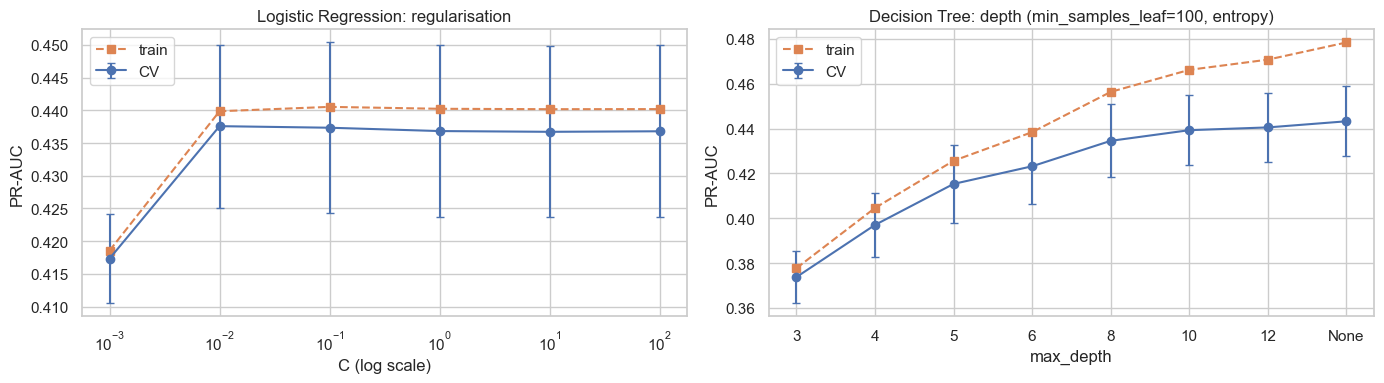

In [42]:
# Tuning curves: CV vs training score as model complexity changes
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
lr_res = pd.DataFrame(searches["Logistic Regression"].cv_results_)
c_values = lr_res["param_model__C"].astype(float)
axes[0].errorbar(c_values, lr_res["mean_test_score"], yerr=lr_res["std_test_score"], marker="o", capsize=3, label="CV")
axes[0].plot(c_values, lr_res["mean_train_score"], marker="s", ls="--", label="train")
axes[0].set(xscale="log", xlabel="C (log scale)", ylabel="PR-AUC", title="Logistic Regression: regularisation")
axes[0].legend()

dt_res = pd.DataFrame(searches["Decision Tree"].cv_results_)
best_dt = searches["Decision Tree"].best_params_
sub = dt_res[(dt_res["param_model__min_samples_leaf"] == best_dt["model__min_samples_leaf"]) &
             (dt_res["param_model__criterion"] == best_dt["model__criterion"])].copy()
sub["depth"] = sub["param_model__max_depth"].astype(object).fillna("None").astype(str)
axes[1].errorbar(sub["depth"], sub["mean_test_score"], yerr=sub["std_test_score"], marker="o", capsize=3, label="CV")
axes[1].plot(sub["depth"], sub["mean_train_score"], marker="s", ls="--", label="train")
axes[1].set(xlabel="max_depth", ylabel="PR-AUC",
            title=f"Decision Tree: depth (min_samples_leaf={best_dt['model__min_samples_leaf']}, {best_dt['model__criterion']})")
axes[1].legend()
save_fig("fig12_tuning_curves")

**What this shows**
- Best: entropy, at least 100 clients per leaf: CV PR-AUC **0.443**.
- In the right chart, the training score keeps rising while CV flattens: a deeper tree starts memorising.

➡️ **Next:** Random Forest.

## 4.3 Random Forest
*Owner: Thulmanthi W.A.S*

**What the code does:** tries 20 random combinations of number of trees, depth, leaf size and features per split (randomised search).

In [43]:
# Randomised search, 20 settings (n_jobs=-1 uses all CPU cores inside the forest)
rf_pipe = Pipeline([("prep", build_preprocessor("tree")),
                    ("model", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))])
rf_space = {"model__n_estimators": [200, 300, 500], "model__max_depth": [8, 12, 16, 20, None],
            "model__min_samples_leaf": [1, 3, 5, 10, 20], "model__max_features": ["sqrt", 0.3, 0.5],
            "model__class_weight": ["balanced", "balanced_subsample"]}
run_search("Random Forest", RandomizedSearchCV(rf_pipe, rf_space, n_iter=20, scoring="average_precision", cv=CV,
                                               return_train_score=True, random_state=RANDOM_STATE))
top_results(searches["Random Forest"])

Random Forest: 20 settings x 5 folds in 1591s
  best CV PR-AUC = 0.4702 ± 0.0176
  best params    = {'model__n_estimators': 300, 'model__min_samples_leaf': 10, 'model__max_features': 0.3, 'model__max_depth': 12, 'model__class_weight': 'balanced'}


,params,cv_pr_auc,cv_std,train_pr_auc,rank_test_score
12,"{'model__n_estimators': 300, 'model__min_samples_leaf': 10, 'model__max_features': 0.3, 'model__max_depth': 12, 'mod...",0.4702,0.0176,0.5900,1
6,"{'model__n_estimators': 300, 'model__min_samples_leaf': 10, 'model__max_features': 'sqrt', 'model__max_depth': 16, '...",0.4700,0.0189,0.5876,2
9,"{'model__n_estimators': 200, 'model__min_samples_leaf': 20, 'model__max_features': 0.3, 'model__max_depth': 12, 'mod...",0.4695,0.0173,0.5493,3
17,"{'model__n_estimators': 300, 'model__min_samples_leaf': 10, 'model__max_features': 'sqrt', 'model__max_depth': 12, '...",0.4690,0.0175,0.5573,4
2,"{'model__n_estimators': 200, 'model__min_samples_leaf': 20, 'model__max_features': 0.3, 'model__max_depth': 16, 'mod...",0.4688,0.0175,0.5691,5


**What this shows**
- Best: 300 trees, depth 12, 10 clients per leaf: CV PR-AUC **0.470** — the best so far.

➡️ **Next:** XGBoost.

## 4.4 XGBoost
*Owner: Thennakoon T.M.S.D*

**What the code does:** tries 25 random combinations of boosting rounds, learning rate, depth and sampling (randomised search); `scale_pos_weight` handles imbalance.

In [44]:
# Randomised search, 25 settings
xgb_pipe = Pipeline([("prep", build_preprocessor("tree")),
                     ("model", XGBClassifier(objective="binary:logistic", eval_metric="aucpr", tree_method="hist",
                                             scale_pos_weight=SCALE_POS_WEIGHT, random_state=RANDOM_STATE, n_jobs=-1))])
xgb_space = {"model__n_estimators": [200, 400, 600, 800], "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
             "model__max_depth": [3, 4, 5, 6], "model__min_child_weight": [1, 3, 5, 10],
             "model__subsample": [0.7, 0.8, 1.0], "model__colsample_bytree": [0.6, 0.8, 1.0],
             "model__gamma": [0, 1], "model__reg_lambda": [1, 5]}
run_search("XGBoost", RandomizedSearchCV(xgb_pipe, xgb_space, n_iter=25, scoring="average_precision", cv=CV,
                                         return_train_score=True, random_state=RANDOM_STATE))
top_results(searches["XGBoost"])

XGBoost: 25 settings x 5 folds in 484s
  best CV PR-AUC = 0.4674 ± 0.0166
  best params    = {'model__subsample': 0.7, 'model__reg_lambda': 1, 'model__n_estimators': 600, 'model__min_child_weight': 5, 'model__max_depth': 5, 'model__learning_rate': 0.01, 'model__gamma': 0, 'model__colsample_bytree': 1.0}


,params,cv_pr_auc,cv_std,train_pr_auc,rank_test_score
20,"{'model__subsample': 0.7, 'model__reg_lambda': 1, 'model__n_estimators': 600, 'model__min_child_weight': 5, 'model__...",0.4674,0.0166,0.5327,1
24,"{'model__subsample': 0.8, 'model__reg_lambda': 1, 'model__n_estimators': 400, 'model__min_child_weight': 3, 'model__...",0.4669,0.0168,0.5248,2
22,"{'model__subsample': 1.0, 'model__reg_lambda': 1, 'model__n_estimators': 600, 'model__min_child_weight': 5, 'model__...",0.4665,0.0142,0.5465,3
16,"{'model__subsample': 0.7, 'model__reg_lambda': 1, 'model__n_estimators': 600, 'model__min_child_weight': 10, 'model_...",0.4665,0.0168,0.5265,4
13,"{'model__subsample': 0.7, 'model__reg_lambda': 5, 'model__n_estimators': 400, 'model__min_child_weight': 3, 'model__...",0.4660,0.0153,0.5399,5


**What this shows**
- Best: 600 rounds, learning rate 0.01, depth 5: CV PR-AUC **0.467** — close to Random Forest.

➡️ **Next:** compare all models.

## 4.5 Model comparison
*Owner: Thennakoon T.M.S.D*

**What the code does:** re-runs cross-validation for the four tuned models and the dummies with all metrics.

In [45]:
# Cross-validate the tuned models and the dummies with all metrics
MODEL_ORDER = ["Logistic Regression", "Decision Tree", "Random Forest", "XGBoost"]
candidates = {"Dummy: always no": reference["Dummy: always no"], "Dummy: random guess": reference["Dummy: random guess"],
              **{name: clone(searches[name].best_estimator_) for name in MODEL_ORDER}}
cv_rows = [evaluate_cv(model, X_train, y_train, name) for name, model in candidates.items()]
cv_df = pd.DataFrame(cv_rows).drop(columns="fold_scores").set_index("model")
cv_table(cv_rows)

,pr_auc,roc_auc,recall,precision,f1,balanced_acc,accuracy,top20_capture
model,,,,,,,,
Dummy: always no,0.113 ± 0.000,0.500 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.887 ± 0.000,0.189 ± 0.005
Dummy: random guess,0.113 ± 0.001,0.502 ± 0.004,0.114 ± 0.006,0.115 ± 0.006,0.115 ± 0.006,0.502 ± 0.004,0.802 ± 0.001,0.199 ± 0.009
Logistic Regression,0.438 ± 0.012,0.787 ± 0.007,0.634 ± 0.014,0.328 ± 0.012,0.432 ± 0.013,0.735 ± 0.009,0.812 ± 0.007,0.620 ± 0.014
Decision Tree,0.443 ± 0.016,0.783 ± 0.005,0.652 ± 0.011,0.315 ± 0.016,0.425 ± 0.015,0.736 ± 0.008,0.800 ± 0.012,0.625 ± 0.013
Random Forest,0.470 ± 0.018,0.801 ± 0.010,0.603 ± 0.013,0.411 ± 0.012,0.489 ± 0.012,0.747 ± 0.007,0.858 ± 0.004,0.643 ± 0.014
XGBoost,0.467 ± 0.017,0.800 ± 0.008,0.631 ± 0.011,0.372 ± 0.010,0.468 ± 0.010,0.748 ± 0.007,0.838 ± 0.004,0.642 ± 0.012


**What the code does:** compares each model with the baseline fold by fold.

In [46]:
# Fold-by-fold comparison with the baseline (same folds for every model)
paired_comparison([r for r in cv_rows if r["model"] in MODEL_ORDER], baseline="Logistic Regression").round(4)

,mean_pr_auc_diff_vs_baseline,std_of_diff,folds_better
model,,,
Decision Tree,0.0057,0.0084,3/5
Random Forest,0.0326,0.0086,5/5
XGBoost,0.0298,0.0064,5/5


**What the code does:** draws bar charts of PR-AUC, ROC-AUC and top-20% capture.

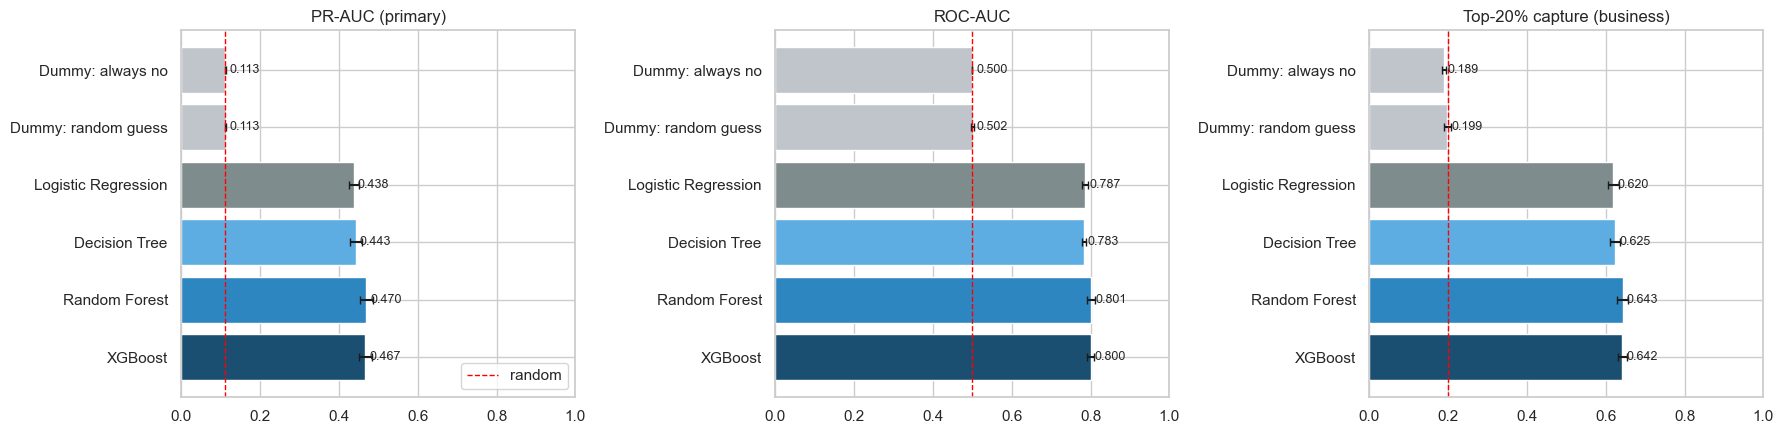

In [47]:
# Bar charts of the three threshold-free metrics
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
palette = ["#c0c5cc", "#c0c5cc", "#7f8c8d", "#5dade2", "#2e86c1", "#1b4f72"]
for ax, (metric, title, ref) in zip(axes, [("pr_auc", "PR-AUC (primary)", y_train.mean()), ("roc_auc", "ROC-AUC", 0.5),
                                          ("top20_capture", "Top-20% capture (business)", 0.2)]):
    ax.barh(cv_df.index, cv_df[f"{metric}_mean"], xerr=cv_df[f"{metric}_std"], color=palette, capsize=3)
    ax.axvline(ref, color="red", ls="--", lw=1, label="random")
    for yi, v in enumerate(cv_df[f"{metric}_mean"]):
        ax.text(v + 0.01, yi, f"{v:.3f}", va="center", fontsize=9)
    ax.set(title=title, xlim=(0, 1))
    ax.invert_yaxis()
axes[0].legend(loc="lower right")
save_fig("fig13_model_comparison_cv")

**What this shows**
- PR-AUC: Logistic Regression 0.438 · Decision Tree 0.443 · **Random Forest 0.470** · XGBoost 0.467.
- Random Forest and XGBoost beat the baseline in **all 5 folds**; the Decision Tree does not reliably.
- → Shortlist: Random Forest and XGBoost.

➡️ **Next:** check overfitting.

## 4.6 Overfitting check
**What the code does:** compares each model's training score with its CV score.

In [48]:
# Train vs CV score of the best setting
overfit = pd.DataFrame([{
    "model": name,
    "train_pr_auc": round(searches[name].cv_results_["mean_train_score"][searches[name].best_index_], 4),
    "cv_pr_auc": round(searches[name].cv_results_["mean_test_score"][searches[name].best_index_], 4),
} for name in MODEL_ORDER]).set_index("model")
overfit["gap"] = overfit["train_pr_auc"] - overfit["cv_pr_auc"]
overfit["gap_%_of_cv"] = (100 * overfit["gap"] / overfit["cv_pr_auc"]).round(1)
overfit

,train_pr_auc,cv_pr_auc,gap,gap_%_of_cv
model,,,,
Logistic Regression,0.4399,0.4376,0.0023,0.5
Decision Tree,0.4784,0.4433,0.0351,7.9
Random Forest,0.5900,0.4702,0.1198,25.5
XGBoost,0.5327,0.4674,0.0653,14.0


**What this shows**
- Gap: LR 0.5%, DT 7.9%, XGBoost 14.0%, Random Forest 25.5%. Random Forest memorises the most but still has the best CV score.

➡️ **Next:** test SMOTE.

## 4.7 SMOTE vs class weights
*Owner: Thulmanthi W.A.S*

**What the code does:** re-runs each tuned model with SMOTE (synthetic "yes" clients, created inside each training fold) instead of class weights.

In [49]:
def smote_version(name):
    # Same tuned model, but SMOTE instead of class weights
    best = searches[name].best_estimator_
    model = clone(best.named_steps["model"])
    model.set_params(**({"scale_pos_weight": 1} if name == "XGBoost" else {"class_weight": None}))
    return ImbPipeline([("prep", clone(best.named_steps["prep"])), ("smote", SMOTE(random_state=RANDOM_STATE)), ("model", model)])

smote_rows = [evaluate_cv(smote_version(name), X_train, y_train, name) for name in MODEL_ORDER]
cw, sm = cv_df.loc[MODEL_ORDER], pd.DataFrame(smote_rows).set_index("model")
pd.DataFrame({"PR-AUC class weights": cw["pr_auc_mean"], "PR-AUC SMOTE": sm["pr_auc_mean"],
              "recall class weights": cw["recall_mean"], "recall SMOTE": sm["recall_mean"],
              "precision class weights": cw["precision_mean"], "precision SMOTE": sm["precision_mean"],
              "top20 class weights": cw["top20_capture_mean"], "top20 SMOTE": sm["top20_capture_mean"],
              "fit time (s) weights": cw["fit_time_s"], "fit time (s) SMOTE": sm["fit_time_s"]}).round(4)

,PR-AUC class weights,PR-AUC SMOTE,recall class weights,recall SMOTE,precision class weights,precision SMOTE,top20 class weights,top20 SMOTE,fit time (s) weights,fit time (s) SMOTE
model,,,,,,,,,,
Logistic Regression,0.4376,0.4378,0.6343,0.6341,0.3279,0.3255,0.6195,0.6182,0.7192,1.4629
Decision Tree,0.4433,0.3815,0.6524,0.4452,0.3150,0.4129,0.6249,0.5780,0.6961,2.3468
Random Forest,0.4702,0.4433,0.6028,0.4646,0.4114,0.4862,0.6430,0.6303,12.1826,34.4556
XGBoost,0.4674,0.4481,0.6314,0.3888,0.3721,0.5183,0.6421,0.6257,4.8328,21.4068


**What this shows**
- SMOTE never improved PR-AUC and made the tree models worse (−0.02 to −0.06), so **class weights are kept**.

## Part 4 summary
| Model | CV PR-AUC | Better than baseline? |
|---|---|---|
| Logistic Regression | 0.438 | – (baseline) |
| Decision Tree | 0.443 | Not reliably (3/5 folds) |
| **Random Forest** | **0.470** | Yes (5/5 folds) |
| XGBoost | 0.467 | Yes (5/5 folds) |

# Part 5 – Evaluation on the Test Set
**Owner:** Thennakoon T.M.S.D

**Goal:** an honest, one-time estimate on clients the models have never seen. **What we do:** score the locked test set, measure
uncertainty, view results as a call list, choose decision thresholds (using training data only) and check each year separately.

## 5.1 Test results
**What the code does:** scores the test set with the four tuned models (and the dummies).

In [50]:
# Test scores of the four tuned models (threshold 0.5 for recall/precision/F1/accuracy)
models = {name: searches[name].best_estimator_ for name in MODEL_ORDER}
test_scores = {name: m.predict_proba(X_test)[:, 1] for name, m in models.items()}
rows = []
for name in ["Dummy: always no", "Dummy: random guess"]:
    d = clone(reference[name]).fit(X_train, y_train)
    rows.append({"model": name, **score_predictions(y_test, d.predict_proba(X_test)[:, 1])})
rows += [{"model": name, **score_predictions(y_test, test_scores[name])} for name in MODEL_ORDER]
test_results = pd.DataFrame(rows).set_index("model")
print(f"Test set: {len(y_test):,} clients, {y_test.sum()} subscribers ({y_test.mean():.2%})")
test_results.drop(columns=["TP", "FP", "FN", "TN"]).round(3)

Test set: 8,236 clients, 928 subscribers (11.27%)


,pr_auc,roc_auc,precision,recall,f1,balanced_acc,accuracy,top20_capture
model,,,,,,,,
Dummy: always no,0.113,0.500,0.000,0.000,0.000,0.500,0.887,0.194
Dummy: random guess,0.116,0.512,0.135,0.133,0.134,0.512,0.807,0.216
Logistic Regression,0.446,0.797,0.338,0.662,0.448,0.749,0.816,0.643
Decision Tree,0.465,0.792,0.303,0.680,0.420,0.741,0.788,0.642
Random Forest,0.496,0.814,0.431,0.637,0.514,0.765,0.864,0.671
XGBoost,0.484,0.814,0.390,0.656,0.490,0.763,0.846,0.665


**What the code does:** compares test scores with the CV scores from Part 4.

In [51]:
# Does the test set agree with cross-validation?
cv_vs_test = pd.DataFrame({"CV PR-AUC": cv_df.loc[MODEL_ORDER, "pr_auc_mean"], "CV std": cv_df.loc[MODEL_ORDER, "pr_auc_std"],
                           "Test PR-AUC": test_results.loc[MODEL_ORDER, "pr_auc"],
                           "CV ROC-AUC": cv_df.loc[MODEL_ORDER, "roc_auc_mean"], "Test ROC-AUC": test_results.loc[MODEL_ORDER, "roc_auc"],
                           "CV top-20%": cv_df.loc[MODEL_ORDER, "top20_capture_mean"],
                           "Test top-20%": test_results.loc[MODEL_ORDER, "top20_capture"]})
cv_vs_test["Test - CV (PR-AUC)"] = cv_vs_test["Test PR-AUC"] - cv_vs_test["CV PR-AUC"]
cv_vs_test["within 2 std?"] = cv_vs_test["Test - CV (PR-AUC)"].abs() <= 2 * cv_vs_test["CV std"]
cv_vs_test.round(4)

,CV PR-AUC,CV std,Test PR-AUC,CV ROC-AUC,Test ROC-AUC,CV top-20%,Test top-20%,Test - CV (PR-AUC),within 2 std?
model,,,,,,,,,
Logistic Regression,0.4376,0.0125,0.4464,0.7868,0.7968,0.6195,0.6433,0.0088,True
Decision Tree,0.4433,0.0156,0.4646,0.7825,0.7923,0.6249,0.6422,0.0214,True
Random Forest,0.4702,0.0176,0.4955,0.8014,0.8137,0.6430,0.6713,0.0253,True
XGBoost,0.4674,0.0166,0.4844,0.8002,0.8137,0.6421,0.6649,0.0170,True


**What this shows**
- Test PR-AUC: LR 0.446 · DT 0.465 · **RF 0.496** · XGB 0.484 (random 0.116).
- All test scores agree with CV, so the models generalise.

➡️ **Next:** is Random Forest really better than XGBoost?

## 5.2 Bootstrap confidence intervals
**What the code does:** resamples the test set 1,000 times to get a 95% range for each model's PR-AUC and for the differences between models.

In [52]:
# 1,000 bootstrap resamples of the test set
N_BOOT = 1000
rng = np.random.default_rng(RANDOM_STATE)
y_arr = y_test.to_numpy()
boot = {name: np.empty(N_BOOT) for name in MODEL_ORDER}
for b in range(N_BOOT):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    for name in MODEL_ORDER:
        boot[name][b] = average_precision_score(y_arr[idx], test_scores[name][idx])

# 95% intervals for each model and for pairwise differences
rows = [{"comparison": n, "PR-AUC (test)": test_results.loc[n, "pr_auc"],
         "95% CI low": np.percentile(boot[n], 2.5), "95% CI high": np.percentile(boot[n], 97.5)} for n in MODEL_ORDER]
for a, b in [("Random Forest", "XGBoost"), ("Random Forest", "Logistic Regression"),
             ("XGBoost", "Logistic Regression"), ("Decision Tree", "Logistic Regression")]:
    diff = boot[a] - boot[b]
    lo, hi = np.percentile(diff, [2.5, 97.5])
    rows.append({"comparison": f"{a} - {b}", "PR-AUC (test)": test_results.loc[a, "pr_auc"] - test_results.loc[b, "pr_auc"],
                 "95% CI low": lo, "95% CI high": hi, "first better in % of resamples": 100 * (diff > 0).mean(),
                 "significant?": "yes" if lo > 0 or hi < 0 else "no (CI contains 0)"})
bootstrap_ci = pd.DataFrame(rows).set_index("comparison")
bootstrap_ci.round(4)

,PR-AUC (test),95% CI low,95% CI high,first better in % of resamples,significant?
comparison,,,,,
Logistic Regression,0.4464,0.4134,0.4824,NaN,NaN
Decision Tree,0.4646,0.4312,0.4994,NaN,NaN
Random Forest,0.4955,0.4605,0.5299,NaN,NaN
XGBoost,0.4844,0.4492,0.5197,NaN,NaN
Random Forest - XGBoost,0.0111,0.0032,0.0187,99.8,yes
Random Forest - Logistic Regression,0.0491,0.0327,0.0658,100.0,yes
XGBoost - Logistic Regression,0.0380,0.0253,0.0524,100.0,yes
Decision Tree - Logistic Regression,0.0182,0.0013,0.0347,98.2,yes


**What this shows**
- Random Forest beats XGBoost by +0.011 (95% CI 0.003 to 0.019) — small but real; both clearly beat the baseline.

➡️ **Next:** view the results as a call list.

## 5.3 ROC, precision–recall and gains
**What the code does:** draws ROC, precision–recall and gains curves; the gains table shows the share of subscribers reached when calling the top x% of clients.

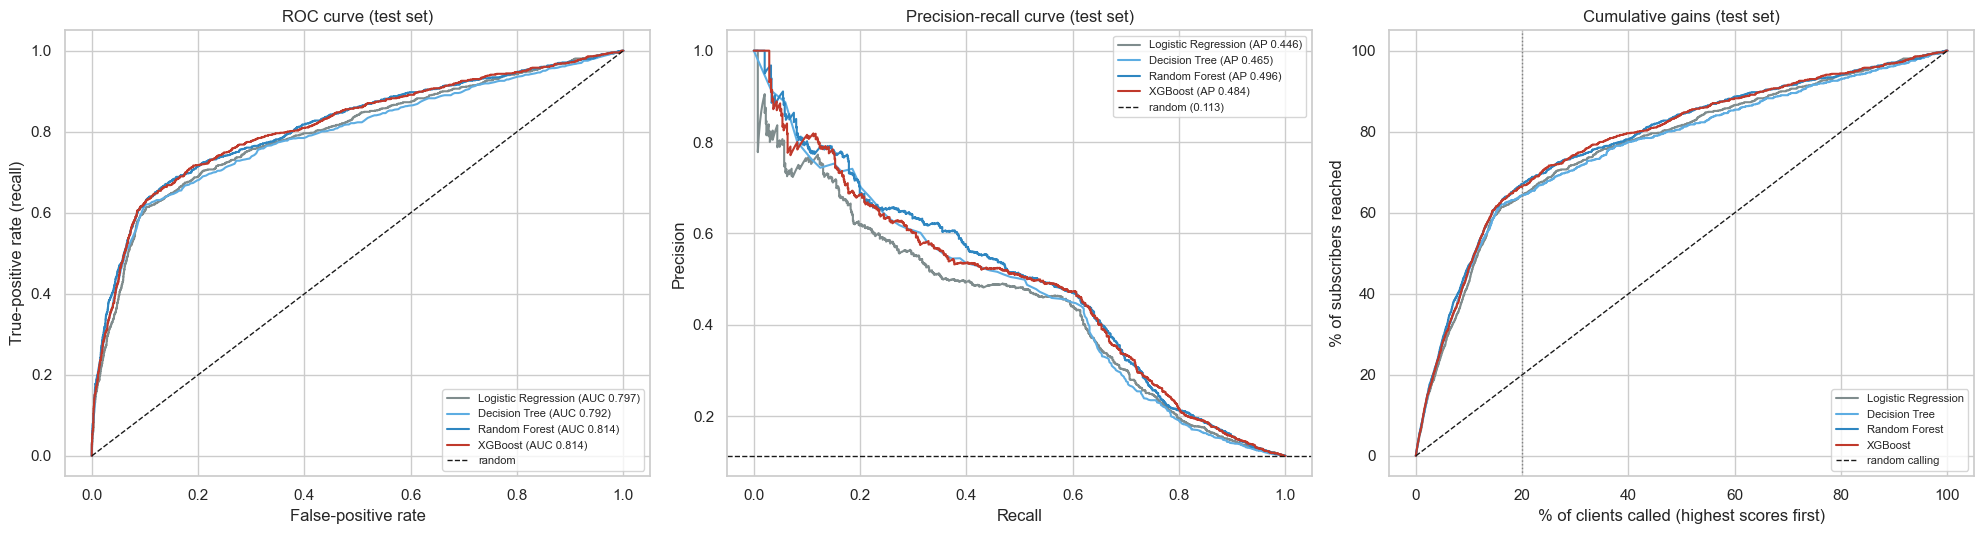

Lift over random calling:


,top 10%,top 20%,top 30%,top 40%,top 50%
Logistic Regression,4.30,3.22,2.40,1.94,1.63
Decision Tree,4.58,3.21,2.36,1.94,1.62
Random Forest,4.72,3.36,2.46,1.95,1.69
XGBoost,4.63,3.32,2.47,1.99,1.69
Random calling,1.00,1.00,1.00,1.00,1.00


,top 10%,top 20%,top 30%,top 40%,top 50%
Logistic Regression,43.0,64.3,72.0,77.7,81.6
Decision Tree,45.8,64.2,70.8,77.5,80.8
Random Forest,47.2,67.1,73.8,78.1,84.4
XGBoost,46.3,66.5,74.2,79.6,84.4
Random calling,10.0,20.0,30.0,40.0,50.0


In [53]:
# ROC, precision-recall and cumulative gains on the test set
COLORS = {"Logistic Regression": "#7f8c8d", "Decision Tree": "#5dade2", "Random Forest": "#2e86c1", "XGBoost": "#c0392b"}
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for name in MODEL_ORDER:
    s = test_scores[name]
    fpr, tpr, _ = roc_curve(y_test, s)
    axes[0].plot(fpr, tpr, color=COLORS[name], label=f"{name} (AUC {roc_auc_score(y_test, s):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, s)
    axes[1].plot(rec, prec, color=COLORS[name], label=f"{name} (AP {average_precision_score(y_test, s):.3f})")
    gains = np.concatenate([[0], np.cumsum(y_arr[np.argsort(-s, kind="stable")]) / y_arr.sum()])
    axes[2].plot(100 * np.arange(len(gains)) / len(y_arr), 100 * gains, color=COLORS[name], label=name)
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="random")
axes[0].set(xlabel="False-positive rate", ylabel="True-positive rate (recall)", title="ROC curve (test set)")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"random ({y_test.mean():.3f})")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curve (test set)")
axes[2].plot([0, 100], [0, 100], "k--", lw=1, label="random calling")
axes[2].axvline(20, color="grey", ls=":", lw=1)
axes[2].set(xlabel="% of clients called (highest scores first)", ylabel="% of subscribers reached", title="Cumulative gains (test set)")
for ax in axes:
    ax.legend(fontsize=8, loc="upper right" if ax is axes[1] else "lower right")
save_fig("fig14_test_roc_pr_gains")

# Share of subscribers reached when calling the top x% (and lift over random calling)
gains_table = pd.DataFrame({name: {f"top {p}%": top_k_capture(y_test, test_scores[name], p / 100) for p in [10, 20, 30, 40, 50]}
                            for name in MODEL_ORDER}).T
gains_table.loc["Random calling"] = [p / 100 for p in [10, 20, 30, 40, 50]]
print("Lift over random calling:")
display(gains_table.div(gains_table.loc["Random calling"], axis=1).round(2))
(100 * gains_table).round(1)

**What this shows**
- Calling the top **20%** of Random Forest's list reaches **67%** of subscribers (3.4× random); the top 10% reaches 47%.

➡️ **Next:** turn scores into call decisions.

## 5.4 Decision thresholds
Three business rules: **Max F1** (best balance), **Recall ≥ 70%**, **Capacity 20%** (call the top 20%). Thresholds are chosen on **training out-of-fold predictions**, never on the test set.

**What the code does:** computes out-of-fold predictions on the training set, picks the three thresholds, and applies them to the test set.

In [54]:
TARGET_RECALL, CAPACITY = 0.70, 0.20

def pick_thresholds(y, p):
    # Threshold for each business rule, from scores and true labels
    prec, rec, thr = precision_recall_curve(y, p)
    prec, rec = prec[:-1], rec[:-1]
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    return {"Max F1": thr[np.argmax(f1)], "Recall >= 70%": thr[rec >= TARGET_RECALL].max(),
            "Capacity 20%": np.quantile(p, 1 - CAPACITY)}

def call_outcome(y, p, t):
    # Business view of a threshold: calls made, subscribers found / missed, wasted calls
    y = np.asarray(y)
    called = p >= t
    hits = int((called & (y == 1)).sum())
    return {"threshold": t, "% of clients called": 100 * called.mean(), "calls": int(called.sum()),
            "subscribers found": hits, "subscribers missed": int(y.sum() - hits), "wasted calls": int(called.sum() - hits),
            "recall": hits / y.sum(), "precision (conversion rate)": hits / max(called.sum(), 1),
            "F1": 2 * hits / (called.sum() + y.sum())}

# Out-of-fold predictions on the training set and the three thresholds per model
THRESH_MODELS = ["Logistic Regression", "Random Forest", "XGBoost"]
oof, thresholds = {}, {}
for name in THRESH_MODELS:
    oof[name] = cross_val_predict(clone(models[name]), X_train, y_train, cv=CV, method="predict_proba")[:, 1]
    thresholds[name] = pick_thresholds(y_train, oof[name])
    print(f"{name:20s} OOF PR-AUC {average_precision_score(y_train, oof[name]):.4f}")
display(pd.DataFrame(thresholds).T.round(4))

# Apply each threshold to the test set
rows = []
for name in THRESH_MODELS:
    rows.append({"model": name, "rule": "Default 0.5", **call_outcome(y_test, test_scores[name], 0.5)})
    rows += [{"model": name, "rule": rule, **call_outcome(y_test, test_scores[name], t)} for rule, t in thresholds[name].items()]
rows.append({"model": "Random calling", "rule": "call everyone", **call_outcome(y_test, np.ones(len(y_test)), 0.5)})
threshold_results = pd.DataFrame(rows).set_index(["model", "rule"])
threshold_results.round(3)

Logistic Regression  OOF PR-AUC 0.4355
Random Forest        OOF PR-AUC 0.4666
XGBoost              OOF PR-AUC 0.4634


,Max F1,Recall >= 70%,Capacity 20%
Logistic Regression,0.6478,0.4131,0.5234
Random Forest,0.5789,0.3644,0.4242
XGBoost,0.6606,0.3934,0.4847


threshold  % of clients called  calls  subscribers found  subscribers missed  wasted calls  recall  precision (conversion rate)     F1
model               rule                                                                                                                                                 
Logistic Regression Default 0.5        0.500               22.050   1816                614                 314          1202   0.662                        0.338  0.448
                    Max F1             0.648               14.546   1198                545                 383           653   0.587                        0.455  0.513
                    Recall >= 70%      0.413               30.427   2506                670                 258          1836   0.722                        0.267  0.390
                    Capacity 20%       0.523               20.265   1669                599                 329          1070   0.645                        0.359  0.461
Random Forest       Default 0.5        0.500               16.646   1371                591                 337           780   0.637                        0.431  0.514
                    Max F1             0.579               14.643   1206                563                 365           643   0.607                        0.467  0.528
                    Recall >= 70%      0.364               28.011   2307                679                 249          1628   0.732                        0.294  0.420
                    Capacity 20%       0.424               20.070   1653                623                 305          1030   0.671                        0.377  0.483
XGBoost             Default 0.5        0.500               18.941   1560                609                 319           951   0.656                        0.390  0.490
                    Max F1             0.661               13.987   1152                548                 380           604   0.591                        0.476  0.527
                    Recall >= 70%      0.393               27.428   2259                670                 258          1589   0.722                        0.297  0.420
                    Capacity 20%       0.485               19.815   1632                616                 312          1016   0.664                        0.377  0.481
Random calling      call everyone      0.500              100.000   8236                928                   0          7308   1.000                        0.113  0.203

**What the code does:** plots precision, recall and F1 against the threshold, with the chosen thresholds marked.

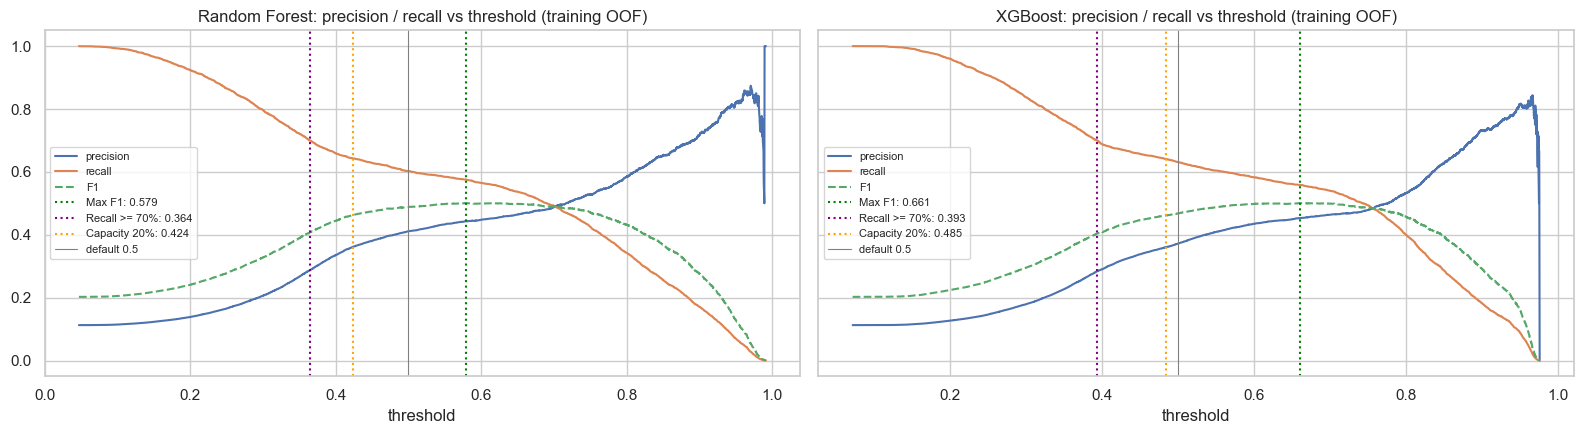

In [55]:
# Precision, recall and F1 across thresholds (training OOF) with the chosen thresholds marked
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), sharey=True)
for ax, name in zip(axes, ["Random Forest", "XGBoost"]):
    prec, rec, thr = precision_recall_curve(y_train, oof[name])
    ax.plot(thr, prec[:-1], label="precision")
    ax.plot(thr, rec[:-1], label="recall")
    ax.plot(thr, 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None), ls="--", label="F1")
    for (rule, t), c in zip(thresholds[name].items(), ["green", "purple", "orange"]):
        ax.axvline(t, color=c, ls=":", lw=1.5, label=f"{rule}: {t:.3f}")
    ax.axvline(0.5, color="grey", lw=0.8, label="default 0.5")
    ax.set(xlabel="threshold", title=f"{name}: precision / recall vs threshold (training OOF)")
    ax.legend(fontsize=8)
save_fig("fig15_threshold_tradeoff")

**What this shows**
- Random Forest, Capacity 20%: 1,653 calls → 623 subscribers (67%), 37.7% of calls succeed.
- Random Forest, Max F1: 1,206 calls → 563 subscribers, 46.7% success.

➡️ **Next:** business view.

## 5.5 Confusion matrices
**What the code does:** shows the confusion matrices at the Max-F1 threshold and compares calls and subscribers with calling everyone.

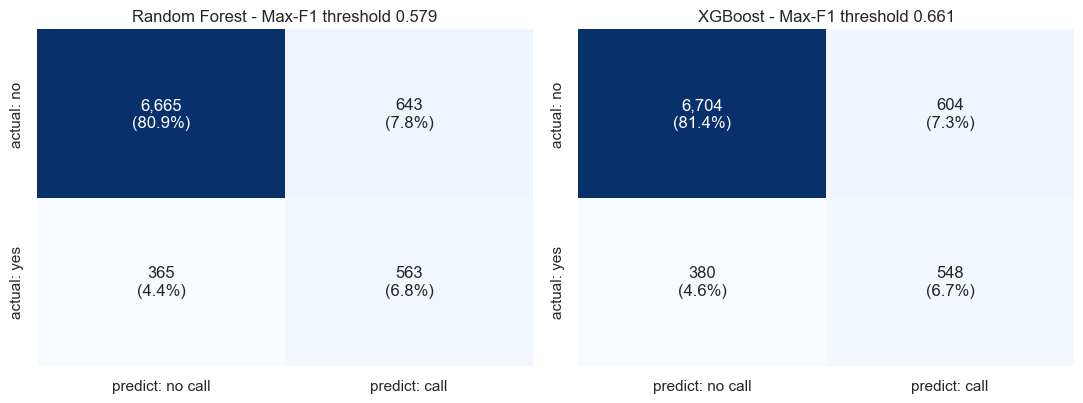

Call everyone: 8,236 calls -> 928 subscribers (conversion 11.3%)
Random Forest Max F1       : 1,206 calls (14.6%) -> 563 subscribers (60.7%), conversion 46.7% = 4.1x calling everyone
Random Forest Capacity 20% : 1,653 calls (20.1%) -> 623 subscribers (67.1%), conversion 37.7% = 3.3x calling everyone
XGBoost       Max F1       : 1,152 calls (14.0%) -> 548 subscribers (59.1%), conversion 47.6% = 4.2x calling everyone
XGBoost       Capacity 20% : 1,632 calls (19.8%) -> 616 subscribers (66.4%), conversion 37.7% = 3.3x calling everyone


In [56]:
# Confusion matrices at the Max-F1 threshold for the two strongest models
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, name in zip(axes, ["Random Forest", "XGBoost"]):
    t = thresholds[name]["Max F1"]
    cm = confusion_matrix(y_test, (test_scores[name] >= t).astype(int), labels=[0, 1])
    sns.heatmap(cm, annot=np.array([[f"{v:,}\n({v / cm.sum():.1%})" for v in r] for r in cm]), fmt="", cmap="Blues", cbar=False,
                ax=ax, xticklabels=["predict: no call", "predict: call"], yticklabels=["actual: no", "actual: yes"])
    ax.set_title(f"{name} - Max-F1 threshold {t:.3f}")
save_fig("fig16_confusion_matrices")

# Calls, subscribers and conversion compared with calling everyone
everyone = call_outcome(y_test, np.ones(len(y_test)), 0.5)
print(f"Call everyone: {everyone['calls']:,} calls -> {everyone['subscribers found']} subscribers "
      f"(conversion {everyone['precision (conversion rate)']:.1%})")
for name in ["Random Forest", "XGBoost"]:
    for rule in ["Max F1", "Capacity 20%"]:
        r = threshold_results.loc[(name, rule)]
        print(f"{name:13s} {rule:13s}: {int(r['calls']):,} calls ({r['% of clients called']:.1f}%) -> {int(r['subscribers found'])} "
              f"subscribers ({r['recall']:.1%}), conversion {r['precision (conversion rate)']:.1%} = "
              f"{r['precision (conversion rate)'] / everyone['precision (conversion rate)']:.1f}x calling everyone")

**What this shows**
- Calling everyone: 8,236 calls, 11.3% success. Random Forest: **4.1×** (Max F1) or 3.3× (Capacity 20%) better success per call.

➡️ **Next:** check each year.

## 5.6 Results per year
**What the code does:** measures ranking quality (ROC-AUC) separately for 2008, 2009 and 2010 test clients.

In [57]:
# Ranking quality within each year of the test set
test_year = year.loc[X_test.index].to_numpy()
rows = []
for yr in sorted(np.unique(test_year)):
    m = test_year == yr
    row = {"year": yr, "test rows": int(m.sum()), "yes-rate %": round(100 * y_arr[m].mean(), 2)}
    row.update({f"{n} ROC-AUC": round(roc_auc_score(y_arr[m], test_scores[n][m]), 3) for n in MODEL_ORDER})
    row.update({f"{n} PR-AUC lift": round(average_precision_score(y_arr[m], test_scores[n][m]) / y_arr[m].mean(), 2) for n in MODEL_ORDER})
    rows.append(row)
per_year = pd.DataFrame(rows).set_index("year")
per_year.T

year,2008,2009,2010
test rows,5566.000,2277.000,393.000
yes-rate %,4.490,20.600,53.180
Logistic Regression ROC-AUC,0.560,0.755,0.688
Decision Tree ROC-AUC,0.537,0.770,0.742
Random Forest ROC-AUC,0.588,0.790,0.744
XGBoost ROC-AUC,0.589,0.784,0.730
Logistic Regression PR-AUC lift,1.290,2.150,1.330
Decision Tree PR-AUC lift,1.500,2.210,1.410
Random Forest PR-AUC lift,2.210,2.420,1.450
XGBoost PR-AUC lift,2.130,2.330,1.430


**What this shows**
- Within a single year ranking is weaker (RF: 0.59, 0.79, 0.74) than the overall 0.81 — 2008 had almost no contact history.
- Random Forest is best or tied-best in every year.

## Part 5 summary
- Random Forest is best on the test set (PR-AUC 0.496), significantly ahead of XGBoost (0.484) and the baseline (0.446).
- Calling the top 20% reaches two thirds of subscribers with 80% fewer calls.
- Performance depends on the period, so the model must be retrained regularly.

# Part 6 – Interpretation and Marketing Profiles
**Owner:** Thulmanthi W.A.S

**Goal (secondary lens):** explain *why* clients are ranked high and turn it into customer profiles; check fairness.
**Methods:** permutation importance, Random Forest feature importance, Logistic Regression odds ratios, a small rule tree, group outcomes.

## 6.1 Permutation importance
**What the code does:** shuffles one feature at a time on the test set and measures how much PR-AUC drops (big drop = important).

In [58]:
# Drop in test PR-AUC when each feature is shuffled (5 repeats)
USED_FEATURES = [c for c in X_test.columns if c not in DROPPED_FEATURES]
perm = {}
perm_std = {}
for name in ["Logistic Regression", "Random Forest", "XGBoost"]:
    r = permutation_importance(models[name], X_test, y_test, scoring="average_precision", n_repeats=5, random_state=RANDOM_STATE)
    perm[name] = pd.Series(r.importances_mean, index=X_test.columns)
    perm_std[name] = pd.Series(r.importances_std, index=X_test.columns)
perm = pd.DataFrame(perm).loc[USED_FEATURES].sort_values("Random Forest", ascending=False)
perm_std = pd.DataFrame(perm_std).loc[perm.index]
print("Agreement between models on the ranking (Spearman):")
display(perm.rank(ascending=False).corr(method="spearman").round(2))
perm.round(4)

Agreement between models on the ranking (Spearman):


,Logistic Regression,Random Forest,XGBoost
Logistic Regression,1.00,0.33,0.43
Random Forest,0.33,1.00,0.96
XGBoost,0.43,0.96,1.00


,Logistic Regression,Random Forest,XGBoost
nr.employed,0.0000,0.0851,0.2124
poutcome,0.0436,0.0590,0.0611
euribor3m,0.2384,0.0589,0.0188
emp.var.rate,0.0000,0.0397,0.0133
contact,0.0116,0.0346,0.0210
day_of_week,0.0041,0.0125,0.0122
campaign,0.0038,0.0117,0.0113
month,0.0251,0.0105,0.0125
cons.conf.idx,0.0060,0.0087,0.0121
cons.price.idx,0.0208,0.0071,0.0059


**What this shows**
- The economic indicators, previous outcome (`poutcome`) and contact type matter most; single personal details (age, job, marital) matter very little.

➡️ **Next:** compare with the forest's own importance.

## 6.2 Random Forest feature importance
*Owner: Thulmanthi W.A.S*

**What the code does:** reads the forest's built-in importance, adds the one-hot columns back to their original feature, and plots it next to permutation importance.

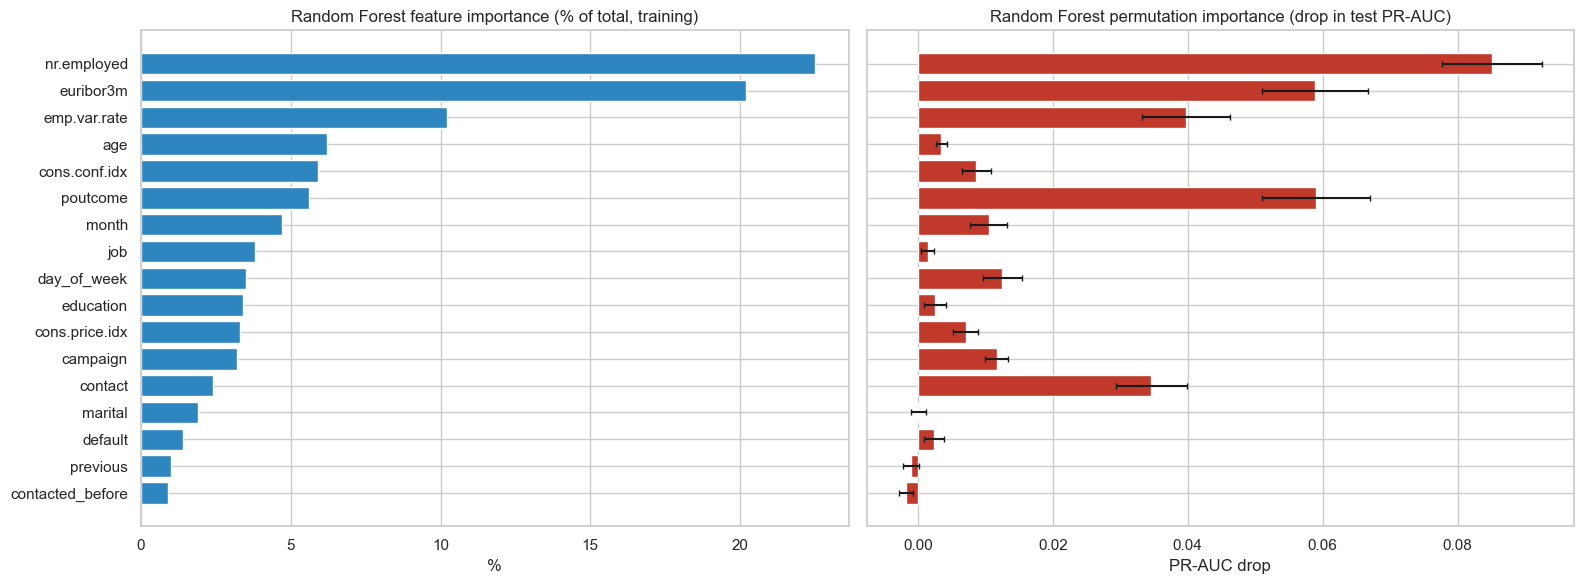

Spearman agreement between the two rankings: 0.72


,RF impurity importance %,RF permutation drop (6.1),rank impurity,rank permutation
nr.employed,22.5,0.0851,1,1
euribor3m,20.2,0.0589,2,3
emp.var.rate,10.2,0.0397,3,4
age,6.2,0.0035,4,11
cons.conf.idx,5.9,0.0087,5,9
poutcome,5.6,0.0590,6,2
month,4.7,0.0105,7,8
job,3.8,0.0015,8,14
day_of_week,3.5,0.0125,9,6
education,3.4,0.0025,10,12


In [59]:
def original_feature(name):
    # Map a one-hot column (e.g. "job_student") back to its original feature ("job")
    for c in CAT_FEATURES:
        if name.startswith(c + "_"):
            return c
    return name

# Impurity-based importance of the tuned Random Forest, grouped to original features (% of total)
rf_model = models["Random Forest"]
rf_imp = pd.Series(rf_model.named_steps["model"].feature_importances_, index=rf_model.named_steps["prep"].get_feature_names_out())
rf_imp = rf_imp.groupby(rf_imp.index.map(original_feature)).sum()
importance = pd.DataFrame({"RF impurity importance %": (100 * rf_imp / rf_imp.sum()).round(1),
                           "RF permutation drop (6.1)": perm["Random Forest"].round(4)}).loc[USED_FEATURES]
importance["rank impurity"] = importance["RF impurity importance %"].rank(ascending=False).astype(int)
importance["rank permutation"] = importance["RF permutation drop (6.1)"].rank(ascending=False).astype(int)
importance = importance.sort_values("RF impurity importance %", ascending=False)

# Side-by-side charts
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
axes[0].barh(importance.index, importance["RF impurity importance %"], color="#2e86c1")
axes[0].set(title="Random Forest feature importance (% of total, training)", xlabel="%")
axes[1].barh(importance.index, importance["RF permutation drop (6.1)"], xerr=perm_std.loc[importance.index, "Random Forest"],
             color="#c0392b", capsize=2)
axes[1].set(title="Random Forest permutation importance (drop in test PR-AUC)", xlabel="PR-AUC drop")
axes[0].invert_yaxis()
save_fig("fig18_rf_vs_permutation_importance")
print("Spearman agreement between the two rankings:",
      round(importance["rank impurity"].corr(importance["rank permutation"], method="spearman"), 2))
importance

**What this shows**
- The five economic indicators make up **62%** of the forest's importance.
- Both methods agree on the main drivers (economy, previous success, contact); built-in importance over-rates features with many values such as age, so permutation importance is the safer guide.

➡️ **Next:** read the baseline's coefficients.

## 6.3 Logistic Regression odds ratios
*Owner: Karunathilaka S.H.T.R*

**What the code does:** turns the baseline's coefficients into odds ratios (above 1 = more likely to subscribe).

In [60]:
# Coefficients of the tuned Logistic Regression as odds ratios
lr = models["Logistic Regression"]
coef = pd.Series(lr.named_steps["model"].coef_[0], index=lr.named_steps["prep"].get_feature_names_out())
odds = pd.DataFrame({"coefficient": coef, "odds_ratio": np.exp(coef)}).sort_values("coefficient")
print("Strongest NEGATIVE effects:")
display(odds.head(10).round(3))
print("Strongest POSITIVE effects:")
odds.tail(10).iloc[::-1].round(3)

Strongest NEGATIVE effects:


,coefficient,odds_ratio
euribor3m,-0.878,0.416
poutcome_failure,-0.698,0.498
month_may,-0.692,0.501
contact_telephone,-0.206,0.814
month_aug,-0.160,0.852
age_41-50,-0.159,0.853
month_nov,-0.157,0.855
age_31-40,-0.152,0.859
default_not_no,-0.113,0.893
job_blue-collar,-0.109,0.897


Strongest POSITIVE effects:


,coefficient,odds_ratio
poutcome_success,0.714,2.042
month_mar,0.605,1.831
month_oct,0.347,1.415
cons.price.idx,0.232,1.261
cons.conf.idx,0.205,1.227
job_retired,0.192,1.212
contact_cellular,0.189,1.208
job_student,0.156,1.169
age_61-70,0.136,1.146
month_dec,0.119,1.127


**What this shows**
- Previous success doubles the odds (×2.04); higher interest rates lower them (×0.42 per step); May halves them (×0.50); mobile, retired and students raise them.

➡️ **Next:** readable customer segments.

## 6.4 Segment rules
*Owner: Jayasuriya J.A.Y.N*

**What the code does:** fits a small 3-level tree on the training set to create IF–THEN segments and checks each segment's yes-rate on the test set — once with all features and once with client features only.

In [61]:
def readable(name, thr, side):
    # Turn a tree split into plain text ("job = student", "age > 60.5")
    feat = original_feature(name)
    if feat != name:
        category = name[len(feat) + 1:]
        return f"{feat} = {category}" if side == ">" else f"{feat} ≠ {category}"
    return f"{name} {'<=' if side == '<=' else '>'} {thr:.4g}"

def leaf_rules(tree, names):
    # The list of conditions leading to each leaf of a fitted tree
    t, rules = tree.tree_, {}
    def walk(node, conds):
        if t.children_left[node] == -1:
            rules[node] = conds
            return
        name, thr = names[t.feature[node]], t.threshold[node]
        walk(t.children_left[node], conds + [readable(name, thr, "<=")])
        walk(t.children_right[node], conds + [readable(name, thr, ">")])
    walk(0, [])
    return rules

def segment_table(drop):
    # Fit a 3-level rule tree on TRAIN (without `drop`) and report each segment's yes-rate on train and test
    pre = build_preprocessor("tree", drop=DROPPED_FEATURES + drop).fit(X_train)
    tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=300, criterion="entropy",
                                  random_state=RANDOM_STATE).fit(pre.transform(X_train), y_train)
    leaf_tr, leaf_te = tree.apply(pre.transform(X_train)), tree.apply(pre.transform(X_test))
    rows = []
    for leaf, conds in leaf_rules(tree, pre.get_feature_names_out()).items():
        tr, te = leaf_tr == leaf, leaf_te == leaf
        rows.append({"segment rule": "  AND  ".join(conds), "train clients": int(tr.sum()),
                     "train yes-rate %": round(100 * y_train[tr].mean(), 1), "test clients": int(te.sum()),
                     "test yes-rate %": round(100 * y_test[te].mean(), 1), "lift (test)": round(y_test[te].mean() / y_test.mean(), 2)})
    out = pd.DataFrame(rows).sort_values("test yes-rate %", ascending=False).reset_index(drop=True)
    out.index = [f"S{i + 1}" for i in range(len(out))]
    return out

print(f"Overall test yes-rate: {100 * y_test.mean():.1f}%")
print("Segments using all features:")
segments_all = segment_table(drop=[])
display(segments_all)
print("Customer-type segments (client + contact-history features only):")
segments_client = segment_table(drop=ECONOMIC_FEATURES + ["month"])
segments_client

Overall test yes-rate: 11.3%
Segments using all features:


,segment rule,train clients,train yes-rate %,test clients,test yes-rate %,lift (test)
S1,nr.employed <= 5088 AND poutcome = success AND nr.employed <= 5013,528,77.1,120,76.7,6.80
S2,nr.employed <= 5088 AND poutcome = success AND nr.employed > 5013,374,65.2,95,64.2,5.70
S3,nr.employed <= 5088 AND poutcome ≠ success AND contact = cellular,2607,38.5,629,41.8,3.71
S4,nr.employed <= 5088 AND poutcome ≠ success AND contact ≠ cellular,478,21.8,131,26.0,2.30
S5,nr.employed > 5088 AND cons.conf.idx <= -46.65 AND poutcome ≠ failure,1667,23.7,451,23.7,2.11
S6,nr.employed > 5088 AND cons.conf.idx <= -46.65 AND poutcome = failure,502,11.0,119,9.2,0.82
S7,nr.employed > 5088 AND cons.conf.idx > -46.65 AND cons.price.idx <= 93.96,17106,6.8,4233,6.5,0.58
S8,nr.employed > 5088 AND cons.conf.idx > -46.65 AND cons.price.idx > 93.96,9678,3.5,2458,3.5,0.31


Customer-type segments (client + contact-history features only):


,segment rule,train clients,train yes-rate %,test clients,test yes-rate %,lift (test)
S1,poutcome = success AND previous > 1.5,401,75.1,107,72.0,6.39
S2,poutcome = success AND previous <= 1.5 AND campaign <= 1.5,372,58.9,88,65.9,5.85
S3,poutcome = success AND previous <= 1.5 AND campaign > 1.5,321,62.9,84,44.0,3.91
S4,poutcome ≠ success AND contact ≠ telephone AND age > 60.5,525,39.6,114,41.2,3.66
S5,poutcome ≠ success AND contact ≠ telephone AND age <= 60.5,19404,11.4,4822,11.6,1.03
S6,poutcome ≠ success AND contact = telephone AND age > 57.5,471,9.3,124,8.9,0.79
S7,poutcome ≠ success AND contact = telephone AND age <= 57.5,11446,4.6,2897,4.8,0.43


**What this shows**
- Customer types: previous subscribers → **66–72%** yes; mobile clients over 60 → **41%**; landline clients under 58 → only **5%** (the largest low group).
- Train and test rates agree, so the profiles hold for new clients.

➡️ **Next:** who is on the top of the call list?

## 6.5 Top-10% clients
**What the code does:** compares the 10% of test clients with the highest Random Forest scores with everyone else.

In [62]:
# Split the test set into the top 10% of RF scores and the rest
rf_scores = test_scores["Random Forest"]
top = rf_scores >= np.quantile(rf_scores, 0.90)
print(f"Top 10%: {top.sum()} clients, actual yes-rate {100 * y_test[top].mean():.1f}% vs {100 * y_test[~top].mean():.1f}% for the rest")

# Typical numeric values in each group
num_cols = ["age", "campaign", "previous", "euribor3m", "nr.employed", "cons.conf.idx"]
num_profile = pd.DataFrame({"top 10% (median)": X_test.loc[top, num_cols].median(),
                            "other 90% (median)": X_test.loc[~top, num_cols].median()})
num_profile.loc["contacted_before (share %)"] = [100 * X_test.loc[top, "contacted_before"].mean(),
                                                100 * X_test.loc[~top, "contacted_before"].mean()]
display(num_profile.round(2))

# Categories over-represented in the top 10%
rows = []
for feat in ["poutcome", "contact", "month", "job", "default", "education", "marital", "day_of_week"]:
    share_top, share_rest = X_test.loc[top, feat].value_counts(normalize=True), X_test.loc[~top, feat].value_counts(normalize=True)
    for cat in share_top.index:
        rows.append({"feature": feat, "category": cat, "share in top 10% (%)": round(100 * share_top[cat], 1),
                     "share in other 90% (%)": round(100 * share_rest.get(cat, 0), 1),
                     "over-representation (x)": round(share_top[cat] / max(share_rest.get(cat, 0), 1e-9), 2)})
top_profile = pd.DataFrame(rows)
top_profile[top_profile["share in top 10% (%)"] >= 5].sort_values("over-representation (x)", ascending=False).head(15)

Top 10%: 824 clients, actual yes-rate 53.2% vs 6.6% for the rest


,top 10% (median),other 90% (median)
age,36.00,38.00
campaign,1.00,2.00
previous,0.00,0.00
euribor3m,0.88,4.86
nr.employed,5017.50,5195.80
cons.conf.idx,-38.30,-41.80
contacted_before (share %),42.84,10.29


,feature,category,share in top 10% (%),share in other 90% (%),over-representation (x)
8,month,mar,11.8,0.2,51.33
1,poutcome,success,27.2,0.7,36.63
9,month,oct,11.8,0.5,22.37
11,month,sep,8.5,0.5,16.15
18,job,student,8.7,1.5,5.78
17,job,retired,13.1,3.0,4.38
6,month,apr,13.6,5.9,2.32
2,poutcome,failure,15.7,9.6,1.64
3,contact,cellular,92.7,59.8,1.55
37,marital,single,41.0,26.6,1.54


**What this shows**
- The top 10% subscribe at **53% vs 7%**; they are mostly contacted in low-interest periods, often contacted before, and on mobile.

➡️ **Next:** fairness check.

## 6.6 Fairness check
*Owner: Jayasuriya J.A.Y.N*

**What the code does:** (a) shows who would be called in each age and marital group at the Capacity-20% rule.

In [63]:
# (a) Group outcomes for Random Forest at the Capacity-20% threshold (from training OOF, 5.4)
t_cap = thresholds["Random Forest"]["Capacity 20%"]
called = rf_scores >= t_cap
age_group = pd.cut(X_test["age"], bins=AGE_BINS, labels=AGE_LABELS)

def group_outcomes(groups, called):
    # Clients, actual yes-rate, share selected, recall and precision per group
    rows = []
    for g in pd.Series(groups).dropna().unique():
        m = np.asarray(groups == g)
        yy, cc = y_arr[m], called[m]
        rows.append({"group": g, "clients": int(m.sum()), "actual yes-rate %": round(100 * yy.mean(), 1),
                     "selection rate %": round(100 * cc.mean(), 1),
                     "recall %": round(100 * (cc & (yy == 1)).sum() / max(yy.sum(), 1), 1),
                     "precision %": round(100 * (cc & (yy == 1)).sum() / max(cc.sum(), 1), 1)})
    return pd.DataFrame(rows).set_index("group")

print(f"Random Forest, Capacity-20% threshold = {t_cap:.3f}")
display(group_outcomes(age_group, called).reindex(AGE_LABELS))
group_outcomes(X_test["marital"], called).sort_values("clients", ascending=False)

Random Forest, Capacity-20% threshold = 0.424


,clients,actual yes-rate %,selection rate %,recall %,precision %
group,,,,,
17-25,328,18.9,46.0,90.3,37.1
26-30,1106,13.8,28.0,70.6,34.8
31-40,3312,10.9,16.7,61.7,40.1
41-50,2021,7.5,12.5,54.3,32.5
51-60,1302,9.4,17.1,61.8,34.2
61-70,92,41.3,98.9,100.0,41.8
71+,75,54.7,97.3,100.0,56.2


,clients,actual yes-rate %,selection rate %,recall %,precision %
group,,,,,
married,5006,9.8,16.8,64.7,37.8
single,2307,14.3,28.8,74.8,37.1
divorced,911,11.4,15.8,54.8,39.6
unknown,12,8.3,8.3,0.0,0.0


**What the code does:** (b) retrains Random Forest without `age` and `marital` and compares results; (c) checks whether this changes who is called.

In [64]:
# (b) Retrain the tuned Random Forest without age and marital and compare on the test set
blind = Pipeline([("prep", build_preprocessor("tree", drop=DROPPED_FEATURES + ["age", "marital"])),
                  ("model", clone(models["Random Forest"].named_steps["model"]))]).fit(X_train, y_train)
blind_scores = blind.predict_proba(X_test)[:, 1]
blind_compare = pd.DataFrame({"Random Forest (all features)": score_predictions(y_test, rf_scores),
                              "Random Forest without age & marital": score_predictions(y_test, blind_scores)}).T[
                              ["pr_auc", "roc_auc", "top20_capture"]]
blind_compare.loc["difference"] = blind_compare.iloc[1] - blind_compare.iloc[0]
display(blind_compare.round(4))

# (c) Selection rate by age group for both models (same rule: top 20% of scores)
proxy_check = pd.DataFrame({label: pd.Series(s >= np.quantile(s, 0.80), index=X_test.index).groupby(age_group, observed=True).mean().mul(100).round(1)
                            for label, s in [("selection % with age & marital", rf_scores),
                                             ("selection % without age & marital", blind_scores)]}).reindex(AGE_LABELS)
proxy_check.insert(0, "clients", age_group.value_counts().reindex(AGE_LABELS))
older = X_test["age"] > 60
print(f"Possible proxies among clients aged 61+: {100 * (X_test.loc[older, 'job'] == 'retired').mean():.1f}% are 'retired'; "
      f"median euribor3m {X_test.loc[older, 'euribor3m'].median():.2f} vs {X_test['euribor3m'].median():.2f} overall")
proxy_check

,pr_auc,roc_auc,top20_capture
Random Forest (all features),0.4955,0.8137,0.6713
Random Forest without age & marital,0.4959,0.8140,0.6703
difference,0.0004,0.0003,-0.0011


Possible proxies among clients aged 61+: 73.1% are 'retired'; median euribor3m 0.85 vs 4.86 overall


,clients,selection % with age & marital,selection % without age & marital
age,,,
17-25,328,46.0,43.6
26-30,1106,27.8,25.4
31-40,3312,16.7,17.1
41-50,2021,12.4,14.0
51-60,1302,17.1,16.5
61-70,92,98.9,98.9
71+,75,97.3,94.7


**What this shows**
- Clients over 60 are called almost always (95–99%) — they really do subscribe more.
- Removing `age` and `marital` costs nothing but hardly changes who is called, because other features (e.g. `retired`) act as proxies → monitoring is needed.

## Part 6 summary
- **Drivers:** economic context first, then previous success and contact channel.
- **Profiles:** previous subscribers, mobile clients over 60, students and retired clients respond best; landline clients under 58 least.
- **Fairness:** removing sensitive columns is not enough; outcomes by group must be monitored.

# Part 7 – Final Model
**Owner:** Thulmanthi W.A.S

**Goal:** choose the final model and the calling rule, then verify that exact configuration on the test set.

## 7.1 Selection matrix
**What the code does:** puts the evidence for all four models in one table (CV, test, confidence intervals, per-year results, overfitting, speed, size).

In [65]:
# All evidence for the four models in one table (from Parts 4-5)
model_mb = {name: len(pickle.dumps(models[name])) / 1e6 for name in MODEL_ORDER}
matrix = pd.DataFrame({
    "CV PR-AUC": cv_df.loc[MODEL_ORDER, "pr_auc_mean"].round(3),
    "Test PR-AUC": test_results.loc[MODEL_ORDER, "pr_auc"].round(3),
    "Test 95% CI": [f"[{bootstrap_ci.loc[m, '95% CI low']:.3f}, {bootstrap_ci.loc[m, '95% CI high']:.3f}]" for m in MODEL_ORDER],
    "Gain vs LR (test)": [np.nan] + [round(bootstrap_ci.loc[f"{m} - Logistic Regression", "PR-AUC (test)"], 3) for m in MODEL_ORDER[1:]],
    "Test ROC-AUC": test_results.loc[MODEL_ORDER, "roc_auc"].round(3),
    "Test top-20% capture": test_results.loc[MODEL_ORDER, "top20_capture"].round(3),
    "Worst within-year ROC-AUC": [per_year[f"{m} ROC-AUC"].min() for m in MODEL_ORDER],
    "Train-CV gap %": overfit.loc[MODEL_ORDER, "gap_%_of_cv"],
    "Fit time / fold (s)": cv_df.loc[MODEL_ORDER, "fit_time_s"].round(1),
    "Model size (MB)": [round(model_mb[m], 2) for m in MODEL_ORDER],
    "Interpretability": ["High (odds ratios)", "High (rules)", "Medium (feature importance)", "Medium (feature importance)"],
}, index=MODEL_ORDER)
matrix.T

,Logistic Regression,Decision Tree,Random Forest,XGBoost
CV PR-AUC,0.438,0.443,0.47,0.467
Test PR-AUC,0.446,0.465,0.496,0.484
Test 95% CI,"[0.413, 0.482]","[0.431, 0.499]","[0.461, 0.530]","[0.449, 0.520]"
Gain vs LR (test),NaN,0.018,0.049,0.038
Test ROC-AUC,0.797,0.792,0.814,0.814
Test top-20% capture,0.643,0.642,0.671,0.665
Worst within-year ROC-AUC,0.56,0.537,0.588,0.589
Train-CV gap %,0.5,7.9,25.5,14.0
Fit time / fold (s),0.7,0.7,12.2,4.8
Model size (MB),0.0,0.04,21.09,1.5


**What this shows**
- Random Forest is best on every performance measure; its costs (larger model, more overfitting) do not matter for scoring a call list.
- **Decision: Random Forest**, with XGBoost as the fallback.

➡️ **Next:** final configuration.

## 7.2 Final configuration
**What the code does:** defines the final pipeline: the tuned Random Forest **without `age` and `marital`** (they added no performance).

In [66]:
# Final pipeline: tuned Random Forest settings, without age and marital
FINAL_DROP = DROPPED_FEATURES + ["age", "marital"]
final_cats, final_nums = feature_lists("tree", drop=FINAL_DROP)

def make_final_model():
    # A fresh, unfitted copy of the final pipeline
    return Pipeline([("prep", build_preprocessor("tree", drop=FINAL_DROP)), ("model", clone(models["Random Forest"].named_steps["model"]))])

rf_params = {k: v for k, v in models["Random Forest"].named_steps["model"].get_params().items()
             if k in ["n_estimators", "max_depth", "min_samples_leaf", "max_features", "class_weight"]}
print("Hyperparameters:", rf_params)
print("Categorical inputs:", final_cats)
print("Numeric inputs:   ", final_nums)
print("Excluded:         ", FINAL_DROP + LEAKAGE_FEATURES + ["pdays (replaced by contacted_before)"])

Hyperparameters: {'class_weight': 'balanced', 'max_depth': 12, 'max_features': 0.3, 'min_samples_leaf': 10, 'n_estimators': 300}
Categorical inputs: ['job', 'education', 'default', 'contact', 'month', 'day_of_week', 'poutcome']
Numeric inputs:    ['campaign', 'previous', 'contacted_before', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Excluded:          ['housing', 'loan', 'age', 'marital', 'duration', 'pdays (replaced by contacted_before)']


## 7.3 Calling rules
**What the code does:** finds the two thresholds on training out-of-fold predictions: **Capacity 20%** (main rule) and **Max F1** (alternative).

In [67]:
# Out-of-fold predictions of the final configuration and its two thresholds
final_oof = cross_val_predict(make_final_model(), X_train, y_train, cv=CV, method="predict_proba")[:, 1]
final_thr = pick_thresholds(y_train, final_oof)
FINAL_THRESHOLDS = {"Capacity 20% (main)": final_thr["Capacity 20%"], "Max F1 (alternative)": final_thr["Max F1"]}
print(f"OOF PR-AUC {average_precision_score(y_train, final_oof):.4f}")
pd.Series(FINAL_THRESHOLDS, name="threshold").round(4)

OOF PR-AUC 0.4658


Capacity 20% (main)     0.4472
Max F1 (alternative)    0.6377
Name: threshold, dtype: float64

## 7.4 Final test check
**What the code does:** trains the final model on the training set, scores the test set once and shows both calling rules in business terms.

In [68]:
# Train the final configuration on the training set and score the test set once
final_model = make_final_model().fit(X_train, y_train)
final_scores = final_model.predict_proba(X_test)[:, 1]
overall = pd.DataFrame({"Final RF (no age/marital)": score_predictions(y_test, final_scores),
                        "Tuned RF (all features, Part 5)": score_predictions(y_test, rf_scores)}).T[
                        ["pr_auc", "roc_auc", "top20_capture", "balanced_acc"]]
display(overall.round(4))

# Both operating rules in business terms
ops = pd.DataFrame({rule: call_outcome(y_test, final_scores, t) for rule, t in FINAL_THRESHOLDS.items()}).T
ops.loc["Call everyone"] = pd.Series(call_outcome(y_test, np.ones(len(y_test)), 0.5))
ops["conversion vs calling everyone (x)"] = ops["precision (conversion rate)"] / ops.loc["Call everyone", "precision (conversion rate)"]
ops.round(3)

,pr_auc,roc_auc,top20_capture,balanced_acc
Final RF (no age/marital),0.4959,0.8140,0.6703,0.7621
"Tuned RF (all features, Part 5)",0.4955,0.8137,0.6713,0.7651


,threshold,% of clients called,calls,subscribers found,subscribers missed,wasted calls,recall,precision (conversion rate),F1,conversion vs calling everyone (x)
Capacity 20% (main),0.447,20.046,1651.0,622.0,306.0,1029.0,0.670,0.377,0.482,3.344
Max F1 (alternative),0.638,13.660,1125.0,536.0,392.0,589.0,0.578,0.476,0.522,4.228
Call everyone,0.500,100.000,8236.0,928.0,0.0,7308.0,1.000,0.113,0.203,1.000


**What the code does:** shows the final model's results per year and per age/marital group.

In [69]:
# Within-year ranking of the final model
final_per_year = pd.DataFrame([{"year": yr, "test rows": int((test_year == yr).sum()),
                                "yes-rate %": round(100 * y_arr[test_year == yr].mean(), 1),
                                "ROC-AUC": round(roc_auc_score(y_arr[test_year == yr], final_scores[test_year == yr]), 3),
                                "PR-AUC lift": round(average_precision_score(y_arr[test_year == yr], final_scores[test_year == yr])
                                                     / y_arr[test_year == yr].mean(), 2)}
                               for yr in sorted(np.unique(test_year))]).set_index("year")
display(final_per_year)

# Group outcomes at the main rule (age and marital are not inputs; used only for monitoring)
final_called = final_scores >= FINAL_THRESHOLDS["Capacity 20% (main)"]
display(group_outcomes(age_group, final_called).reindex(AGE_LABELS))
group_outcomes(X_test["marital"], final_called).sort_values("clients", ascending=False)

,test rows,yes-rate %,ROC-AUC,PR-AUC lift
year,,,,
2008,5566,4.5,0.592,2.30
2009,2277,20.6,0.788,2.43
2010,393,53.2,0.745,1.45


,clients,actual yes-rate %,selection rate %,recall %,precision %
group,,,,,
17-25,328,18.9,43.6,87.1,37.8
26-30,1106,13.8,25.4,69.9,38.1
31-40,3312,10.9,17.1,62.2,39.5
41-50,2021,7.5,14.0,54.3,29.1
51-60,1302,9.4,16.6,62.6,35.6
61-70,92,41.3,98.9,100.0,41.8
71+,75,54.7,94.7,97.6,56.3


,clients,actual yes-rate %,selection rate %,recall %,precision %
group,,,,,
married,5006,9.8,17.6,65.1,36.4
single,2307,14.3,26.8,73.6,39.3
divorced,911,11.4,16.2,55.8,39.2
unknown,12,8.3,8.3,0.0,0.0


**What this shows**
- Final model: PR-AUC **0.496**, ROC-AUC 0.814 — the same as with age and marital.
- **Capacity 20%:** 1,651 calls → 622 of 928 subscribers (67%), 37.7% success (3.3× calling everyone).
- **Max F1:** 1,125 calls → 536 subscribers, 47.6% success (4.2×).

# Conclusion
- **Final model:** Random Forest (300 trees, depth 12) using 15 inputs available before a call.
- **Result:** calling the top 20% of the ranked list makes **80% fewer calls**, still reaches **two thirds of subscribers**, and raises success per call from **11% to 38%**.
- **Main drivers:** economic conditions, previous campaign success and mobile contact.
- **Limitations:** results depend on the period (retrain before each campaign); data is from one bank in 2008–2010; older clients are selected far more often, so outcomes must be monitored.

The full decision log, model comparison, recommendations and limitations are in the final report.

**References:** Moro, Cortez & Rita (2014), *Decision Support Systems* 62, 22–31 · UCI Bank Marketing dataset · scikit-learn, XGBoost, imbalanced-learn.